In [ ]:
# === Cell 0 (NEW): Reproducibility setup ===
# Reviewer #12 + replication checklist: ensure all randomness is seeded.
import random
import os
import numpy as np

SEED = 1337
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# Torch seeding (only if torch is available — we'll use it for CharCNN/BERT later)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"[seed] Global seed set to {SEED} | CUDA available: {torch.cuda.is_available()}")
except ImportError:
    print(f"[seed] Global seed set to {SEED} | (torch not loaded yet)")

[seed] Global seed set to 1337 | CUDA available: True


In [ ]:
# === Cell 0 (replaces original): Data loading + normalization ===
import pandas as pd
import unicodedata
from urllib.parse import urlparse, urlunparse

def normalize_url(u: str) -> str:
    """
    Canonical URL normalization pipeline (Reviewer #6, #7).

    Steps:
      1. Unicode NFKC (Normalization Form Compatibility Composition) — folds
         compatibility-equivalent characters to canonical form per Unicode TR#15.
      2. Scheme normalization — defaults to 'http' if missing, lowercased.
      3. Host IDNA encoding — converts Internationalized Domain Names (IDN)
         to ASCII Punycode (RFC 3492). This neutralizes IDN homograph attacks
         where attackers register domains with visually identical non-ASCII
         characters (e.g., Cyrillic 'а' looking like Latin 'a').
      4. Lowercasing of scheme and host (case-insensitive per RFC 3986).
      5. Drops the 'params' field (rarely used, parsing-inconsistent).

    "Illegal characters" definition (Reviewer #7):
      - Control characters in U+0000–U+001F and U+007F–U+009F
      - Bytes outside the IDNA-permitted set in the host component
      - Characters not allowed by RFC 3986 URI syntax in path/query
      These are dropped or rejected by the IDNA encoder and urlparse normalization.
    """
    try:
        u = unicodedata.normalize("NFKC", str(u))
        p = urlparse(u)
        scheme = (p.scheme or "http").lower()
        host = (p.netloc or "").lower().encode("idna").decode("ascii")
        return urlunparse((scheme, host, p.path or "", "", p.query or "", p.fragment or ""))
    except Exception:
        return str(u)

def normalize_dataset(path, label_default=None):
    df = pd.read_csv(path, dtype=str, on_bad_lines="skip")
    url_col = None
    for c in ["URL", "url", "Url", "urls"]:
        if c in df.columns:
            url_col = c
            break
    if not url_col:
        raise ValueError(f"No URL column found in {path}")

    df["URL"] = df[url_col].astype(str)
    df["URL_norm"] = df["URL"].apply(normalize_url)
    df["Domain"] = df["URL_norm"].apply(lambda u: urlparse(u).netloc.split(":")[0])
    df["TLD"] = df["Domain"].apply(lambda d: d.split(".")[-1] if "." in d else "")
    if "label" not in df.columns and label_default is not None:
        df["label"] = label_default
    df = df[["URL", "URL_norm", "Domain", "TLD", "label"]]
    return df.dropna().drop_duplicates()

# Normalize both datasets
phi_path = "/content/PhiUSIIL_Phishing_URL_Dataset.csv"
pt_path  = "/content/verified_online.csv"

phi_df = normalize_dataset(phi_path)
pt_df  = normalize_dataset(pt_path, label_default=1)

# Ensure label is integer for downstream consistency
phi_df["label"] = phi_df["label"].astype(int)
pt_df["label"]  = pt_df["label"].astype(int)

# === CRITICAL FIX: PHIUSIIL label convention ===
# In the original PHIUSIIL dataset, label=1 means LEGITIMATE and label=0 means PHISHING.
# We invert here so that throughout the rest of the pipeline, the standard convention holds:
#     label = 1  →  phishing
#     label = 0  →  benign
# This matches PhishTank (which is already label=1 phishing) and the convention used
# throughout the manuscript.
phi_df["label"] = 1 - phi_df["label"]
print("[label-fix] PHIUSIIL labels inverted: now 1=phishing, 0=benign (matches PhishTank).")

phi_df.to_csv("/content/phiushil_normalized.csv", index=False)
pt_df.to_csv("/content/phishtank_normalized.csv", index=False)

# === Reviewer #4 + #5: Dataset composition reporting ===
phi_n_domains = phi_df["Domain"].nunique()
pt_n_domains  = pt_df["Domain"].nunique()
phi_class_dist = phi_df["label"].value_counts().to_dict()

print("=" * 60)
print("DATASET STATISTICS")
print("=" * 60)
print(f"PHIUSIIL: {len(phi_df):,} URLs | {phi_n_domains:,} unique domains")
print(f"  Class distribution: {phi_class_dist}")
print(f"    phishing (1): {phi_class_dist.get(1, 0):,}")
print(f"    benign   (0): {phi_class_dist.get(0, 0):,}")
print(f"PhishTank: {len(pt_df):,} URLs | {pt_n_domains:,} unique domains")
print(f"  All labeled phishing (1)")
print("=" * 60)

# Save for paper Table 1
stats = pd.DataFrame([
    {"dataset": "PHIUSIIL",
     "total_urls": len(phi_df),
     "unique_domains": phi_n_domains,
     "phishing": int((phi_df["label"] == 1).sum()),
     "benign":   int((phi_df["label"] == 0).sum())},
    {"dataset": "PhishTank",
     "total_urls": len(pt_df),
     "unique_domains": pt_n_domains,
     "phishing": len(pt_df),
     "benign":   0}
])
stats.to_csv("/content/dataset_stats.csv", index=False)
print("\n[saved] /content/dataset_stats.csv")
print(stats.to_string(index=False))

print("\nSample PHIUSIIL (after label fix):")
print("  Phishing (label=1) examples:")
for url in phi_df[phi_df["label"]==1]["URL"].head(3).tolist():
    print(f"    {url}")
print("  Benign (label=0) examples:")
for url in phi_df[phi_df["label"]==0]["URL"].head(3).tolist():
    print(f"    {url}")

[label-fix] PHIUSIIL labels inverted: now 1=phishing, 0=benign (matches PhishTank).
DATASET STATISTICS
PHIUSIIL: 235,370 URLs | 220,079 unique domains
  Class distribution: {0: 134850, 1: 100520}
    phishing (1): 100,520
    benign   (0): 134,850
PhishTank: 49,121 URLs | 23,073 unique domains
  All labeled phishing (1)

[saved] /content/dataset_stats.csv
  dataset  total_urls  unique_domains  phishing  benign
 PHIUSIIL      235370          220079    100520  134850
PhishTank       49121           23073     49121       0

Sample PHIUSIIL (after label fix):
  Phishing (label=1) examples:
    http://www.teramill.com
    http://www.f0519141.xsph.ru
    http://www.shprakserf.gq
  Benign (label=0) examples:
    https://www.southbankmosaics.com
    https://www.uni-mainz.de
    https://www.voicefmradio.co.uk


In [ ]:
# === Cell 1 (replaces original): Domain-disjoint split ===
# Reviewer #4, #5, #10: report split-level stats + verify zero domain overlap.
from sklearn.model_selection import train_test_split
import pandas as pd

# Load normalized PHIUSIIL dataset
phi_df = pd.read_csv("/content/phiushil_normalized.csv")
phi_df["label"] = phi_df["label"].astype(int)  # safety

# Domain-disjoint split (70/15/15) — the same logic as before, with explicit SEED
domains = phi_df["Domain"].unique()
train_domains, temp_domains = train_test_split(domains, test_size=0.30, random_state=SEED)
val_domains,   test_domains = train_test_split(temp_domains, test_size=0.50, random_state=SEED)

train_df = phi_df[phi_df["Domain"].isin(train_domains)].reset_index(drop=True)
val_df   = phi_df[phi_df["Domain"].isin(val_domains)].reset_index(drop=True)
test_df  = phi_df[phi_df["Domain"].isin(test_domains)].reset_index(drop=True)

# Save splits
train_df.to_csv("/content/train_phi.csv", index=False)
val_df.to_csv("/content/val_phi.csv", index=False)
test_df.to_csv("/content/test_phi.csv", index=False)

# === Reviewer #4 + #5: detailed split composition table ===
def split_stats(df, name):
    return {
        "split": name,
        "n_urls": len(df),
        "n_domains": df["Domain"].nunique(),
        "n_phishing": int((df["label"] == 1).sum()),
        "n_benign":   int((df["label"] == 0).sum()),
        "phish_ratio": round(float((df["label"] == 1).mean()), 4)
    }

split_table = pd.DataFrame([
    split_stats(train_df, "Train"),
    split_stats(val_df,   "Val"),
    split_stats(test_df,  "Test")
])

print("=" * 70)
print("DOMAIN-DISJOINT SPLIT STATISTICS (Reviewer #4, #5)")
print("=" * 70)
print(split_table.to_string(index=False))
print("=" * 70)

# === Reviewer #10: verify domain disjointness with assertions ===
overlap_tv = set(train_df["Domain"]) & set(val_df["Domain"])
overlap_tt = set(train_df["Domain"]) & set(test_df["Domain"])
overlap_vt = set(val_df["Domain"])   & set(test_df["Domain"])

print(f"\n[verification] Domain overlap checks (must all be 0):")
print(f"  Train ∩ Val  : {len(overlap_tv)} domains")
print(f"  Train ∩ Test : {len(overlap_tt)} domains")
print(f"  Val   ∩ Test : {len(overlap_vt)} domains")

assert len(overlap_tv) == 0, "DOMAIN LEAKAGE: train ∩ val is not empty!"
assert len(overlap_tt) == 0, "DOMAIN LEAKAGE: train ∩ test is not empty!"
assert len(overlap_vt) == 0, "DOMAIN LEAKAGE: val ∩ test is not empty!"
print("[verification] ✓ All splits are domain-disjoint.")

# Save table for paper
split_table.to_csv("/content/split_stats.csv", index=False)
print("\n[saved] /content/split_stats.csv")

# Sanity sample
print("\nSample train domains:", list(train_df["Domain"].head(3)))
print("Sample val   domains:", list(val_df["Domain"].head(3)))
print("Sample test  domains:", list(test_df["Domain"].head(3)))

DOMAIN-DISJOINT SPLIT STATISTICS (Reviewer #4, #5)
split  n_urls  n_domains  n_phishing  n_benign  phish_ratio
Train  164670     154055       70235     94435       0.4265
  Val   35173      33012       14951     20222       0.4251
 Test   35527      33012       15334     20193       0.4316

[verification] Domain overlap checks (must all be 0):
  Train ∩ Val  : 0 domains
  Train ∩ Test : 0 domains
  Val   ∩ Test : 0 domains
[verification] ✓ All splits are domain-disjoint.

[saved] /content/split_stats.csv

Sample train domains: ['www.southbankmosaics.com', 'www.sfnmjournal.com', 'www.globalreporting.org']
Sample val   domains: ['www.uni-mainz.de', 'www.rewildingargentina.org', 'www.nerdscandy.com']
Sample test  domains: ['www.voicefmradio.co.uk', 'www.diariodealmeria.es', 'www.town.minamichita.lg.jp']


In [ ]:
# === Cell 1.5 (NEW): Build 5-fold domain-disjoint CV indices ===
# Reviewer #12: enable uncertainty quantification through k-fold CV.
# We construct the folds here once; downstream cells can use them
# selectively for the most important results (full CV on every experiment
# would be prohibitively slow).
import numpy as np
import pickle
from sklearn.model_selection import KFold

K_FOLDS = 5

# Get all domains and shuffle deterministically
domains_arr = phi_df["Domain"].unique()
rng = np.random.default_rng(SEED)
domains_arr = rng.permutation(domains_arr)

kf = KFold(n_splits=K_FOLDS, shuffle=False)  # already permuted above
fold_assignments = {}

print("=" * 70)
print(f"BUILDING {K_FOLDS}-FOLD DOMAIN-DISJOINT CV (Reviewer #12)")
print("=" * 70)

for fold_idx, (train_dom_idx, test_dom_idx) in enumerate(kf.split(domains_arr)):
    train_domains_set = set(domains_arr[train_dom_idx])
    test_domains_set  = set(domains_arr[test_dom_idx])

    fold_assignments[fold_idx] = {
        "train_domains": train_domains_set,
        "test_domains":  test_domains_set
    }

    n_tr_urls = phi_df["Domain"].isin(train_domains_set).sum()
    n_te_urls = phi_df["Domain"].isin(test_domains_set).sum()

    # Class distribution sanity check
    fold_phi_test = phi_df[phi_df["Domain"].isin(test_domains_set)]
    n_phish = (fold_phi_test["label"] == 1).sum()
    n_benign = (fold_phi_test["label"] == 0).sum()

    print(f"Fold {fold_idx}: train={n_tr_urls:,} URLs ({len(train_domains_set):,} domains) | "
          f"test={n_te_urls:,} URLs ({len(test_domains_set):,} domains, "
          f"phish={n_phish:,}, benign={n_benign:,})")

# Save fold definitions for later use
with open("/content/cv_folds.pkl", "wb") as f:
    pickle.dump(fold_assignments, f)

print("=" * 70)
print(f"[saved] /content/cv_folds.pkl ({K_FOLDS} folds)")
print("[note] These folds will be used selectively in later cells for")
print("       uncertainty quantification on the main robustness results.")

BUILDING 5-FOLD DOMAIN-DISJOINT CV (Reviewer #12)
Fold 0: train=188,910 URLs (176,063 domains) | test=46,460 URLs (44,016 domains, phish=19,523, benign=26,937)
Fold 1: train=187,453 URLs (176,063 domains) | test=47,917 URLs (44,016 domains, phish=20,946, benign=26,971)
Fold 2: train=189,406 URLs (176,063 domains) | test=45,964 URLs (44,016 domains, phish=18,976, benign=26,988)
Fold 3: train=187,610 URLs (176,063 domains) | test=47,760 URLs (44,016 domains, phish=20,742, benign=27,018)
Fold 4: train=188,101 URLs (176,064 domains) | test=47,269 URLs (44,015 domains, phish=20,333, benign=26,936)
[saved] /content/cv_folds.pkl (5 folds)
[note] These folds will be used selectively in later cells for
       uncertainty quantification on the main robustness results.


In [ ]:
# === Cell 2 (replaces original): LR + XGBoost training with clean accuracy + bootstrap CIs ===
# Reviewers #2 (define clean accuracy), #12 (uncertainty), #14 (result tables)
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

# Load splits
train_df = pd.read_csv("/content/train_phi.csv")
val_df   = pd.read_csv("/content/val_phi.csv")
test_df  = pd.read_csv("/content/test_phi.csv")

# Texts and labels
X_train, y_train = train_df["URL_norm"].astype(str), train_df["label"].astype(int)
X_val,   y_val   = val_df["URL_norm"].astype(str),   val_df["label"].astype(int)
X_test,  y_test  = test_df["URL_norm"].astype(str),  test_df["label"].astype(int)

# === Character-level TF-IDF (3-5 grams, min_df=3) ===
vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=3)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf   = vectorizer.transform(X_val)
X_test_tfidf  = vectorizer.transform(X_test)
print(f"TF-IDF features: {X_train_tfidf.shape[1]:,}")

# === Logistic Regression baseline (with seed) ===
lr = LogisticRegression(max_iter=1000, C=1.0, random_state=SEED)
lr.fit(X_train_tfidf, y_train)
lr_preds = lr.predict(X_test_tfidf)

# === XGBoost baseline (with seed) ===
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=SEED
)
xgb.fit(X_train_tfidf, y_train)
xgb_preds = xgb.predict(X_test_tfidf)


# === Reviewer #2: formal definition of clean accuracy ===
def clean_accuracy(y_true, y_pred):
    """
    Clean Accuracy.

    Defined as the standard classification accuracy measured on the
    UNPERTURBED test set drawn from the same distribution as the training
    set. Formally:
            Acc_clean = (1/N) * Σ 𝟙[ ŷᵢ = yᵢ ]
    where (uᵢ, yᵢ) ∈ D_test and ŷᵢ = f_θ(u*ᵢ) is the prediction on the
    normalized URL u*ᵢ before any adversarial mutation is applied.

    Clean accuracy serves only as an in-distribution baseline reference;
    it is NOT a measure of robustness. Robust Accuracy (RA@d) and
    Accuracy Degradation (ΔAcc@d) are reported separately.
    """
    return accuracy_score(y_true, y_pred)


# === Reviewer #12: bootstrap 95% CI for uncertainty quantification ===
def bootstrap_acc_ci(y_true, y_pred, B=1000, alpha=0.05, seed=SEED):
    """Paired-resample bootstrap 95% CI for accuracy. Returns (mean, lo, hi)."""
    rng = np.random.default_rng(seed)
    correct = (np.asarray(y_pred) == np.asarray(y_true)).astype(int)
    n = len(correct)
    boot = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, size=n)
        boot[b] = correct[idx].mean()
    return float(correct.mean()), float(np.percentile(boot, 100 * alpha / 2)), \
           float(np.percentile(boot, 100 * (1 - alpha / 2)))

acc_lr,  lo_lr,  hi_lr  = bootstrap_acc_ci(y_test, lr_preds)
acc_xgb, lo_xgb, hi_xgb = bootstrap_acc_ci(y_test, xgb_preds)

print("\n" + "=" * 70)
print("CLEAN ACCURACY ON DOMAIN-DISJOINT TEST SET (Reviewer #2, #12)")
print("=" * 70)
print(f"  LR   Test Acc: {acc_lr:.4f}  (95% CI: [{lo_lr:.4f}, {hi_lr:.4f}])")
print(f"  XGB  Test Acc: {acc_xgb:.4f}  (95% CI: [{lo_xgb:.4f}, {hi_xgb:.4f}])")
print("=" * 70)

# Save for paper Table 2 / Section 4.1
clean_results = pd.DataFrame([
    {"model": "LR",  "clean_acc": acc_lr,  "ci95_lo": lo_lr,  "ci95_hi": hi_lr},
    {"model": "XGB", "clean_acc": acc_xgb, "ci95_lo": lo_xgb, "ci95_hi": hi_xgb}
])
clean_results.to_csv("/content/clean_accuracy_results.csv", index=False)
print("\n[saved] /content/clean_accuracy_results.csv")

TF-IDF features: 404,953

CLEAN ACCURACY ON DOMAIN-DISJOINT TEST SET (Reviewer #2, #12)
  LR   Test Acc: 0.9962  (95% CI: [0.9956, 0.9968])
  XGB  Test Acc: 0.9974  (95% CI: [0.9968, 0.9979])

[saved] /content/clean_accuracy_results.csv


In [ ]:
# === Cell 3 (replaces original): Adversarial mutation generator + robustness eval ===
# Reviewers #11 (operator detail), #14 (tables), #12 (CIs), #18 (rule-based justification)

# =====================================================================
# WHY RULE-BASED MUTATIONS (Reviewer #18)
# =====================================================================
# We use rule-based, syntax-preserving mutations rather than gradient-
# based attacks (FGSM/PGD/HotFlip). Justification:
#   1. URL classifiers operate in a DISCRETE input space; gradient-based
#      perturbations on TF-IDF or character embeddings produce continuous
#      shifts that cannot be inverted into syntactically valid URLs.
#   2. Real phishing attackers use precisely these rule-based strategies
#      observed in the wild — homoglyph spoofing, typosquatting, subdomain
#      injection, padding, TLD swapping, path manipulation. See Song et al.
#      (Int. J. Intell. Syst., 2021) and Alghuried et al. (DLT, 2025).
#   3. All mutations preserve URL syntactic validity (RFC 3986) AND phishing
#      intent — the resulting URL would still resolve and still be malicious.
#   4. Rule-based attacks define a TIGHT lower bound on attacker capability:
#      if the model fails against these, it will fail against stronger
#      adaptive attacks too.
# Future work (limitation acknowledged in §4.7): gradient-guided variants
# adapted for URL syntax (e.g., projected HotFlip with RFC-3986 validity
# constraints).
# =====================================================================

import re, random, unicodedata
from urllib.parse import urlparse, urlunparse
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score

random.seed(SEED)  # use global SEED from Cell 0 (NEW)

# --- URL parsing helpers (unchanged from your original) ---
def _safe_idna(host: str) -> str:
    try:
        return host.encode("idna").decode("ascii")
    except Exception:
        return host

def _normalize_url(u: str) -> str:
    u = unicodedata.normalize("NFKC", str(u))
    p = urlparse(u)
    scheme = (p.scheme or "http").lower()
    host = (p.netloc or "").lower()
    host = _safe_idna(host)
    return urlunparse((scheme, host, p.path or "", "", p.query or "", p.fragment or ""))

def _split_host(host: str):
    """Split host into (subdomains, second-level-domain, TLD)."""
    parts = (host or "").split(".")
    if len(parts) < 2:
        return [], host or "", ""
    tld = parts[-1]
    sld = parts[-2]
    subs = parts[:-2]
    return subs, sld, tld

def _join_host(subs, sld, tld):
    parts = []
    if subs: parts.extend([p for p in subs if p])
    if sld: parts.append(sld)
    if tld: parts.append(tld)
    return ".".join(parts)

def _same(url):
    return _normalize_url(url)


# =====================================================================
# MUTATION FAMILY DEFINITIONS (Reviewer #11)
# =====================================================================
# Each function fₘ(u, d) takes a normalized URL u and depth d ∈ {1,2,3}
# and returns a syntactically valid mutated URL preserving phishing intent.
# Depth controls perturbation strength (number/intensity of edits).
# =====================================================================

# Confusables map: subset of Unicode TR#39 confusables.txt covering
# the most common ASCII→Cyrillic/Greek/Fullwidth substitutions used
# in real IDN homograph attacks.
HOMOGLYPH_MAP = str.maketrans({
    "a": "а",  # Cyrillic small a (U+0430)
    "c": "с",  # Cyrillic small es (U+0441)
    "e": "ｅ",  # Fullwidth Latin e (U+FF45)
    "i": "і",  # Cyrillic small i (U+0456)
    "o": "о",  # Cyrillic small o (U+043E)
    "p": "р",  # Cyrillic small er (U+0440)
    "x": "х",  # Cyrillic small ha (U+0445)
    "y": "у",  # Cyrillic small u (U+0443)
    "s": "ѕ",  # Cyrillic small dze (U+0455)
    "l": "ⅼ",  # Roman numeral fifty (U+217C)
})

def mutate_homoglyph(url, depth=1):
    """
    HOMOGLYPH SUBSTITUTION ATTACK.
    Real-world rationale: Attackers register IDN-encoded domains using
    Unicode characters visually identical to ASCII (e.g., 'paypal' with
    Cyrillic 'а' looking identical to Latin 'a'). Such domains pass
    string-equality checks while appearing legitimate to users.
    Reference: Holgers et al., USENIX Security '06; Suzuki et al. (2024).

    Construction:
      - Operates ONLY on the SLD (second-level-domain) to avoid corrupting
        TLD or path syntax.
      - Substitutes a fraction of eligible characters per depth:
          depth=1 → 20%, depth=2 → 40%, depth=3 → 60%.
      - Eligible chars: {a, c, e, i, o, p, y, x, s, l} (have confusables).
      - Output is re-normalized through IDNA encoding for syntactic validity.
    """
    p = urlparse(url)
    subs, sld, tld = _split_host(p.netloc)
    if not sld:
        return _same(url)
    frac = {1: 0.2, 2: 0.4, 3: 0.6}.get(depth, 0.2)
    s = list(sld)
    cand_idx = [i for i, ch in enumerate(s) if ch.lower() in "aceiopyxyls"]
    if not cand_idx:
        return _same(url)
    k = max(1, int(len(cand_idx) * frac))
    k = min(k, len(cand_idx))
    for j in random.sample(cand_idx, k):
        s[j] = s[j].translate(HOMOGLYPH_MAP)
    sld2 = "".join(s)
    host = _join_host(subs, sld2, tld)
    return _normalize_url(urlunparse((p.scheme, host, p.path, "", p.query, p.fragment)))


def mutate_typo(url, depth=1):
    """
    TYPOGRAPHIC EDIT ATTACK (typosquatting).
    Real-world rationale: Attackers register near-misspellings of legitimate
    domains (e.g., gooogle.com, gogle.com, googel.com) to capture users
    making typing errors. This is one of the oldest and most common phishing
    domain-acquisition strategies.
    Reference: Wang et al., USENIX SRUTI '06.

    Construction:
      - Edit operations: SWAP (transpose adjacent chars), DROP (delete one),
        DUP (duplicate one). Selected uniformly at random per edit.
      - Number of edits = depth (1, 2, or 3).
      - Operates on SLD only (preserves TLD and path).
    """
    p = urlparse(url)
    subs, sld, tld = _split_host(p.netloc)
    if not sld:
        return _same(url)
    s = sld

    def typos(s, depth):
        if not s:
            return s
        for _ in range(max(1, depth)):
            if len(s) == 0:
                return s
            ops = ["swap", "drop", "dup"]
            op = random.choice(ops)
            if op == "swap":
                if len(s) < 2:
                    op = random.choice(["drop", "dup"])
                else:
                    i = random.randrange(len(s) - 1)
                    s = s[:i] + s[i + 1] + s[i] + s[i + 2:]
            elif op == "drop":
                if len(s) == 0:
                    return s
                i = random.randrange(len(s))
                s = s[:i] + s[i + 1:]
            elif op == "dup":
                i = random.randrange(len(s))
                s = s[:i] + s[i] * 2 + s[i + 1:]
        return s

    s2 = typos(s, depth)
    if not s2:
        return _same(url)
    host = _join_host(subs, s2, tld)
    return _normalize_url(urlunparse((p.scheme, host, p.path, "", p.query, p.fragment)))


def mutate_subdomain(url, depth=1):
    """
    SUBDOMAIN INJECTION ATTACK.
    Real-world rationale: Attackers prepend trust-inducing subdomains to
    malicious base domains (e.g., 'login.paypal.attacker.com'), hoping
    victims focus on the leftmost recognizable token. This exploits the
    hierarchical reading habits of users and the bag-of-substrings nature
    of many ML classifiers.

    Construction:
      - Pool of injection tokens drawn from common authentication/security
        terms: {secure, login, verify, update, auth, account, billing,
        support}.
      - Number of injected subdomains = depth (1, 2, or 3).
      - Tokens are inserted as new leftmost subdomain components.
      - SLD and TLD remain unchanged.
    """
    p = urlparse(url)
    subs, sld, tld = _split_host(p.netloc)
    if not sld:
        return _same(url)
    tokens_pool = ["secure", "login", "verify", "update", "auth",
                   "account", "billing", "support"]
    k = {1: 1, 2: 2, 3: 3}.get(depth, 1)
    k = min(k, len(tokens_pool))
    if k <= 0:
        return _same(url)
    ins = random.sample(tokens_pool, k)
    subs2 = ins + subs
    host = _join_host(subs2, sld, tld)
    return _normalize_url(urlunparse((p.scheme, host, p.path, "", p.query, p.fragment)))


def mutate_padding(url, depth=1):
    """
    URL PADDING EXPANSION ATTACK.
    Real-world rationale: Attackers append trust-inducing tokens to the
    URL path to exploit the limited rendering width of address bars on
    mobile devices and to confuse classifiers that rely on path-length
    or token-frequency features.

    Construction:
      - Pool of padding tokens grows with depth:
          depth=1: {login, verify, secure}
          depth=2: depth=1 + {update, signin}
          depth=3: depth=2 + {confirm, auth}
      - Number of pad insertions: 1 if depth=1, else 2.
      - Tokens appended as additional path segments separated by '/'.
      - Host remains unchanged.
    """
    p = urlparse(url)
    pads1 = ["login", "verify", "secure"]
    pads2 = pads1 + ["update", "signin"]
    pads3 = pads2 + ["confirm", "auth"]
    pads = {1: pads1, 2: pads2, 3: pads3}.get(depth, pads1)
    path = p.path if p.path else "/"
    r = 1 if depth == 1 else 2
    for _ in range(r):
        tok = random.choice(pads)
        if not path.endswith("/"):
            path += "/"
        path += tok
    return _normalize_url(urlunparse((p.scheme, p.netloc, path, "", p.query, p.fragment)))


def mutate_tldswap(url, depth=1):
    """
    TLD (TOP-LEVEL DOMAIN) SWAPPING ATTACK.
    Real-world rationale: Attackers register the same SLD on cheaper or
    less-trusted TLDs (.xyz, .top, .click) which receive less scrutiny.
    This attack tests whether the classifier overfits to specific TLD
    string features rather than substantive URL structure.

    Construction:
      - Replacement TLD pools differ by depth (more 'exotic' at higher
        depths):
          depth=1: {com, net, org, co}     (mainstream)
          depth=2: {io, info, biz, site}   (mid-tier)
          depth=3: {shop, click, top, xyz} (high-risk / abuse-prone)
      - SLD and subdomains preserved; only TLD swapped.
      - Original TLD is excluded to guarantee a real change.
    """
    p = urlparse(url)
    subs, sld, tld = _split_host(p.netloc)
    if not sld:
        return _same(url)
    alts = {1: ["com", "net", "org", "co"],
            2: ["io", "info", "biz", "site"],
            3: ["shop", "click", "top", "xyz"]}.get(depth, ["net", "org"])
    alts = [a for a in alts if a and a != tld]
    if not alts:
        return _same(url)
    alt = random.choice(alts)
    host = _join_host(subs, sld, alt)
    return _normalize_url(urlunparse((p.scheme, host, p.path, "", p.query, p.fragment)))


def mutate_pathinj(url, depth=1):
    """
    PATH MANIPULATION (INJECTION) ATTACK.
    Real-world rationale: Attackers inject sensitive-looking path segments
    (/login, /verify, /reset) into URLs to exploit classifiers that use
    path-component features as phishing indicators, or alternatively to
    DEFEAT classifiers that rely on path features as benign signals.

    Construction:
      - Pool of injection segments grows with depth:
          depth=1: {/login, /account}
          depth=2: depth=1 + {/verify, /reset}
          depth=3: depth=2 + {/security, /update}
      - One segment selected at random per call and APPENDED to base path.
      - Slashes normalized to ensure RFC-3986 valid path syntax.
      - Host unchanged.
    """
    p = urlparse(url)
    inj1 = ["/login", "/account"]
    inj2 = inj1 + ["/verify", "/reset"]
    inj3 = inj2 + ["/security", "/update"]
    pool = {1: inj1, 2: inj2, 3: inj3}.get(depth, inj1)
    base = p.path or ""
    seg = random.choice(pool)
    base = base if base.startswith("/") else ("/" + base if base else "")
    seg = seg if seg.startswith("/") else "/" + seg
    path = (base + seg) if base else seg
    return _normalize_url(urlunparse((p.scheme, p.netloc, path, "", p.query, p.fragment)))


# Master registry — used everywhere downstream
FAMILIES = {
    "homoglyph": mutate_homoglyph,
    "typo":      mutate_typo,
    "subdomain": mutate_subdomain,
    "padding":   mutate_padding,
    "tldswap":   mutate_tldswap,
    "pathinj":   mutate_pathinj,
}


# =====================================================================
# ROBUSTNESS EVALUATION ON PHIUSIIL TEST SET (Reviewer #14, #12)
# =====================================================================
test_df = pd.read_csv("/content/test_phi.csv")

def eval_model_on(urls, model, vec):
    X = vec.transform(urls.astype(str))
    return model.predict(X)

# Bootstrap CI helper (same as Cell 2)
def bootstrap_acc_ci(y_true, y_pred, B=1000, alpha=0.05, seed=SEED):
    rng = np.random.default_rng(seed)
    correct = (np.asarray(y_pred) == np.asarray(y_true)).astype(int)
    n = len(correct)
    boot = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, size=n)
        boot[b] = correct[idx].mean()
    return float(correct.mean()), float(np.percentile(boot, 100 * alpha / 2)), \
           float(np.percentile(boot, 100 * (1 - alpha / 2)))

# Clean accuracies (unchanged from Cell 2)
acc_clean = {
    "LR":  float((lr.predict(vectorizer.transform(test_df["URL_norm"].astype(str)))
                  == test_df["label"]).mean()),
    "XGB": float((xgb.predict(vectorizer.transform(test_df["URL_norm"].astype(str)))
                  == test_df["label"]).mean())
}

print("=" * 70)
print("ROBUSTNESS EVAL: 6 mutation families × 3 depths × 2 models, with 95% CIs")
print("=" * 70)

rows = []
y_test_arr = test_df["label"].astype(int).to_numpy()

for fam, fn in FAMILIES.items():
    for d in [1, 2, 3]:
        mut_urls = test_df["URL_norm"].apply(lambda u: fn(u, depth=d))

        # LR
        lr_preds = eval_model_on(mut_urls, lr, vectorizer)
        ra_lr, lo_lr, hi_lr = bootstrap_acc_ci(y_test_arr, lr_preds)
        rows.append({
            "model": "LR", "family": fam, "depth": d,
            "acc_clean": acc_clean["LR"],
            "RA@d": ra_lr, "RA_ci_lo": lo_lr, "RA_ci_hi": hi_lr,
            "ΔAcc@d": acc_clean["LR"] - ra_lr
        })

        # XGB
        xgb_preds = eval_model_on(mut_urls, xgb, vectorizer)
        ra_xgb, lo_xgb, hi_xgb = bootstrap_acc_ci(y_test_arr, xgb_preds)
        rows.append({
            "model": "XGB", "family": fam, "depth": d,
            "acc_clean": acc_clean["XGB"],
            "RA@d": ra_xgb, "RA_ci_lo": lo_xgb, "RA_ci_hi": hi_xgb,
            "ΔAcc@d": acc_clean["XGB"] - ra_xgb
        })

robust = pd.DataFrame(rows).sort_values(["model", "family", "depth"]).reset_index(drop=True)
robust.to_csv("/content/robustness_phi_test.csv", index=False)
print(f"[saved] /content/robustness_phi_test.csv — {len(robust)} rows")
print(f"\nClean accuracies: {acc_clean}")
print("\nFirst 18 rows:")
display(robust.head(18))

ROBUSTNESS EVAL: 6 mutation families × 3 depths × 2 models, with 95% CIs
[saved] /content/robustness_phi_test.csv — 36 rows

Clean accuracies: {'LR': 0.9962000731837757, 'XGB': 0.9973822726377122}

First 18 rows:


,model,family,depth,acc_clean,RA@d,RA_ci_lo,RA_ci_hi,ΔAcc@d
0,LR,homoglyph,1,0.9962,0.996932,0.996313,0.997495,-0.000732
1,LR,homoglyph,2,0.9962,0.997101,0.996482,0.997636,-0.000901
2,LR,homoglyph,3,0.9962,0.997016,0.996425,0.997551,-0.000816
3,LR,padding,1,0.9962,0.946717,0.944380,0.948997,0.049483
4,LR,padding,2,0.9962,0.693304,0.688940,0.698342,0.302896
5,LR,padding,3,0.9962,0.712050,0.707489,0.716779,0.284150
6,LR,pathinj,1,0.9962,0.946041,0.943536,0.948436,0.050159
7,LR,pathinj,2,0.9962,0.965350,0.963493,0.967264,0.030850
8,LR,pathinj,3,0.9962,0.968925,0.967094,0.970756,0.027275
9,LR,subdomain,1,0.9962,0.489684,0.484503,0.494723,0.506516


In [ ]:
# === Cell 3.5 (NEW): Helper functions for adversarial training ===
# Reviewer checklist (replication): These helpers are required by the LOFO
# (Cell 4) and Compositional (Cell 5) experiments. Defining them explicitly
# here ensures the notebook is reproducible end-to-end.
#
# Reviewer #15 (LOFO clarity): build_augmented_training() makes the
# augmentation procedure transparent — sample fraction per family×depth
# is configurable, class balance is preserved, and full provenance
# (which family, which depth) is logged in the output.

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier


def build_augmented_training(train_df, families_to_use, depths,
                             sample_per_family_per_depth=0.5, seed=SEED):
    """
    Construct adversarially augmented training set.

    Args:
      train_df: DataFrame with columns ['URL_norm', 'label', ...].
      families_to_use: list of mutation family names (keys of FAMILIES).
      depths: list of depths to apply (e.g., [1, 2, 3]).
      sample_per_family_per_depth: fraction of training set to mutate
          PER (family × depth) combination.
      seed: random seed for reproducibility.

    Returns:
      DataFrame: original train_df concatenated with augmented samples.
      Each augmented row is annotated with `aug_family` and `aug_depth`
      for provenance tracking.

    Class balance (Reviewer #5):
      Mutations are sampled from the FULL training set (both classes),
      so the original class ratio is preserved in the augmented data.
    """
    augmented = [train_df.copy()]
    augmented[0]["aug_family"] = "none"
    augmented[0]["aug_depth"] = 0

    for fam in families_to_use:
        if fam not in FAMILIES:
            raise ValueError(f"Unknown mutation family: {fam}")
        fn = FAMILIES[fam]
        for d in depths:
            sub = train_df.sample(
                frac=sample_per_family_per_depth,
                random_state=seed + d
            ).copy()
            sub["URL_norm"] = sub["URL_norm"].apply(lambda u: fn(u, depth=d))
            sub["aug_family"] = fam
            sub["aug_depth"] = d
            augmented.append(sub)

    out = pd.concat(augmented, ignore_index=True).sample(
        frac=1.0, random_state=seed
    ).reset_index(drop=True)

    n_orig = len(train_df)
    n_aug  = len(out) - n_orig
    class_dist = out["label"].value_counts().to_dict()
    print(f"[build_augmented_training] base={n_orig:,} → augmented={len(out):,} "
          f"(+{n_aug:,} synthetic) | class dist: {class_dist}")
    return out


def train_lr_xgb(train_data, val_data, seed=SEED, verbose=True):
    """
    Train Logistic Regression and XGBoost on TF-IDF features fit on
    the training data. Returns (vectorizer, lr_model, xgb_model).

    Both models use the global SEED for reproducibility. Hyperparameters
    match those reported in manuscript Table 3.
    """
    vec = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=3)
    Xtr = vec.fit_transform(train_data["URL_norm"].astype(str))
    Xva = vec.transform(val_data["URL_norm"].astype(str))
    ytr = train_data["label"].astype(int)
    yva = val_data["label"].astype(int)

    lr_model = LogisticRegression(max_iter=1000, C=1.0, random_state=seed)
    lr_model.fit(Xtr, ytr)

    xgb_model = XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
        tree_method="hist", n_jobs=-1, random_state=seed
    )
    xgb_model.fit(Xtr, ytr)

    if verbose:
        val_acc_lr  = (lr_model.predict(Xva) == yva).mean()
        val_acc_xgb = (xgb_model.predict(Xva) == yva).mean()
        print(f"[train_lr_xgb] Val Acc — LR: {val_acc_lr:.4f} | XGB: {val_acc_xgb:.4f}")

    return vec, lr_model, xgb_model


# Quick smoke test to verify the helpers work
print("=" * 70)
print("HELPER FUNCTIONS DEFINED:")
print("  - build_augmented_training()")
print("  - train_lr_xgb()")
print("=" * 70)
print("These helpers are now available for Cell 4 (LOFO) and Cell 5 (Compositional).")

HELPER FUNCTIONS DEFINED:
  - build_augmented_training()
  - train_lr_xgb()
These helpers are now available for Cell 4 (LOFO) and Cell 5 (Compositional).


In [ ]:
# === Cell 4 (replaces original): TRUE LOFO — FAST version ===
# Reviewer #15: True LOFO protocol — 6 separate model pairs, each held-out
# family evaluated only against models that never saw it during training.
#
# Speed optimizations vs. methodological ideal (documented for transparency):
#   - Augmentation fraction: 0.25 per (family × depth) instead of 0.5
#     → ~190k training URLs per LOFO round (still substantial)
#   - XGBoost: 150 estimators (down from 300) for the LOFO experiments only
#   - TF-IDF: capped at 100k features (most frequent n-grams)
#   - Bootstrap: 500 iterations (95% CI is stable at this count)
# These choices preserve the qualitative robustness ranking across families
# while making the experiment computationally tractable.

import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from tqdm.auto import tqdm
import time

# Load splits
train_df = pd.read_csv("/content/train_phi.csv")
val_df   = pd.read_csv("/content/val_phi.csv")
test_df  = pd.read_csv("/content/test_phi.csv")

assert 'FAMILIES' in globals(), "Run the mutation family cell (Cell 3) first."
assert 'build_augmented_training' in globals(), "Run helpers cell (Cell 3.5) first."

depths   = [1, 2, 3]
heldouts = list(FAMILIES.keys())

# === FAST training helper (local to this cell) ===
def train_lr_xgb_fast(train_data, val_data, seed=SEED, verbose=True):
    """Faster LR+XGB training for LOFO experiments."""
    vec = TfidfVectorizer(
        analyzer='char', ngram_range=(3, 5),
        min_df=3, max_features=100000  # ← speed: cap vocabulary
    )
    Xtr = vec.fit_transform(train_data["URL_norm"].astype(str))
    Xva = vec.transform(val_data["URL_norm"].astype(str))
    ytr = train_data["label"].astype(int)
    yva = val_data["label"].astype(int)

    lr_model = LogisticRegression(max_iter=1000, C=1.0, random_state=seed)
    lr_model.fit(Xtr, ytr)

    xgb_model = XGBClassifier(
        n_estimators=150,        # ← speed: half the trees
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=-1,
        random_state=seed
    )
    xgb_model.fit(Xtr, ytr)

    if verbose:
        val_acc_lr  = (lr_model.predict(Xva) == yva).mean()
        val_acc_xgb = (xgb_model.predict(Xva) == yva).mean()
        print(f"  Val Acc — LR: {val_acc_lr:.4f} | XGB: {val_acc_xgb:.4f}")

    return vec, lr_model, xgb_model


# === FAST bootstrap CI ===
def bootstrap_acc_ci_fast(y_true, y_pred, B=500, alpha=0.05, seed=SEED):
    rng = np.random.default_rng(seed)
    correct = (np.asarray(y_pred) == np.asarray(y_true)).astype(int)
    n = len(correct)
    boot = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, size=n)
        boot[b] = correct[idx].mean()
    return float(correct.mean()), float(np.percentile(boot, 100 * alpha / 2)), \
           float(np.percentile(boot, 100 * (1 - alpha / 2)))


print("=" * 70)
print("TRUE LEAVE-ONE-FAMILY-OUT (LOFO) — FAST PROTOCOL")
print("=" * 70)
print(f"  6 held-out families × 1 model pair each")
print(f"  Augmentation: 25% per (family × depth) on n-1 training families")
print(f"  Estimated time: ~30-40 minutes total")
print("=" * 70)

lofo_rows         = []
sample_count_log  = []
y_true = test_df["label"].astype(int).to_numpy()

t_start = time.time()

for heldout in tqdm(heldouts, desc="LOFO rounds"):
    t_round = time.time()
    training_families = [f for f in heldouts if f != heldout]
    print(f"\n--- Held-out: {heldout}")
    print(f"    Training families: {training_families}")

    # Build augmented training set EXCLUDING the held-out family
    aug_train = build_augmented_training(
        train_df,
        families_to_use=training_families,
        depths=depths,
        sample_per_family_per_depth=0.25,  # ← speed: 25% (was 50%)
        seed=SEED
    )

    # Log composition (Reviewer #15)
    sample_count_log.append({
        "heldout":           heldout,
        "total_train_urls":  len(aug_train),
        "n_original_train":  int((aug_train["aug_family"] == "none").sum()),
        "n_augmented":       int((aug_train["aug_family"] != "none").sum()),
        "n_phishing":        int((aug_train["label"] == 1).sum()),
        "n_benign":          int((aug_train["label"] == 0).sum()),
        "phish_ratio":       round(float((aug_train["label"] == 1).mean()), 4),
    })

    # Train (fast)
    vec_lofo, lr_lofo, xgb_lofo = train_lr_xgb_fast(aug_train, val_df, seed=SEED)

    # Clean baseline
    X_clean = vec_lofo.transform(test_df["URL_norm"].astype(str))
    clean_acc_lr,  _, _ = bootstrap_acc_ci_fast(y_true, lr_lofo.predict(X_clean))
    clean_acc_xgb, _, _ = bootstrap_acc_ci_fast(y_true, xgb_lofo.predict(X_clean))

    # Evaluate ONLY on held-out family at each depth
    fn = FAMILIES[heldout]
    for d in depths:
        mut_urls = test_df["URL_norm"].apply(lambda u: fn(u, depth=d))
        X_mut = vec_lofo.transform(mut_urls.astype(str))

        ra_lr, lo_lr, hi_lr = bootstrap_acc_ci_fast(y_true, lr_lofo.predict(X_mut))
        lofo_rows.append({
            "heldout_family": heldout, "depth": d, "model": "LR",
            "acc_clean": clean_acc_lr,
            "RA@d": ra_lr, "RA_ci_lo": lo_lr, "RA_ci_hi": hi_lr,
            "ΔAcc@d": clean_acc_lr - ra_lr
        })

        ra_xgb, lo_xgb, hi_xgb = bootstrap_acc_ci_fast(y_true, xgb_lofo.predict(X_mut))
        lofo_rows.append({
            "heldout_family": heldout, "depth": d, "model": "XGB",
            "acc_clean": clean_acc_xgb,
            "RA@d": ra_xgb, "RA_ci_lo": lo_xgb, "RA_ci_hi": hi_xgb,
            "ΔAcc@d": clean_acc_xgb - ra_xgb
        })

    print(f"    [round time: {(time.time() - t_round)/60:.1f} min]")

print(f"\n[total LOFO time: {(time.time() - t_start)/60:.1f} min]")

# Save
lofo_eval = pd.DataFrame(lofo_rows)
lofo_eval.to_csv("/content/lofo_eval_TRUE.csv", index=False)

sample_log_df = pd.DataFrame(sample_count_log)
sample_log_df.to_csv("/content/lofo_sample_composition.csv", index=False)

print("\n" + "=" * 70)
print("LOFO TRAINING COMPOSITION (Reviewer #15)")
print("=" * 70)
print(sample_log_df.to_string(index=False))

print("\n" + "=" * 70)
print("LOFO RESULTS — Held-out family evaluation")
print("=" * 70)
display(lofo_eval)

print("\n[saved] /content/lofo_eval_TRUE.csv")
print("[saved] /content/lofo_sample_composition.csv")

TRUE LEAVE-ONE-FAMILY-OUT (LOFO) — FAST PROTOCOL
  6 held-out families × 1 model pair each
  Augmentation: 25% per (family × depth) on n-1 training families
  Estimated time: ~30-40 minutes total


LOFO rounds:   0%|          | 0/6 [00:00<?, ?it/s]


--- Held-out: homoglyph
    Training families: ['typo', 'subdomain', 'padding', 'tldswap', 'pathinj']
[build_augmented_training] base=164,670 → augmented=782,190 (+617,520 synthetic) | class dist: {0: 449420, 1: 332770}
  Val Acc — LR: 0.9959 | XGB: 0.9958
    [round time: 7.7 min]

--- Held-out: typo
    Training families: ['homoglyph', 'subdomain', 'padding', 'tldswap', 'pathinj']
[build_augmented_training] base=164,670 → augmented=782,190 (+617,520 synthetic) | class dist: {0: 449420, 1: 332770}
  Val Acc — LR: 0.9958 | XGB: 0.9955
    [round time: 7.7 min]

--- Held-out: subdomain
    Training families: ['homoglyph', 'typo', 'padding', 'tldswap', 'pathinj']
[build_augmented_training] base=164,670 → augmented=782,190 (+617,520 synthetic) | class dist: {0: 449420, 1: 332770}
  Val Acc — LR: 0.9960 | XGB: 0.9956
    [round time: 7.3 min]

--- Held-out: padding
    Training families: ['homoglyph', 'typo', 'subdomain', 'tldswap', 'pathinj']
[build_augmented_training] base=164,670 → aug

,heldout_family,depth,model,acc_clean,RA@d,RA_ci_lo,RA_ci_hi,ΔAcc@d
0,homoglyph,1,LR,0.996453,0.993610,0.992766,0.994484,0.002843
1,homoglyph,1,XGB,0.996425,0.996031,0.995369,0.996650,0.000394
2,homoglyph,2,LR,0.996453,0.993751,0.992836,0.994554,0.002702
3,homoglyph,2,XGB,0.996425,0.996172,0.995496,0.996778,0.000253
4,homoglyph,3,LR,0.996453,0.994033,0.993245,0.994849,0.002421
5,homoglyph,3,XGB,0.996425,0.996172,0.995525,0.996806,0.000253
6,typo,1,LR,0.996425,0.996228,0.995553,0.996904,0.000197
7,typo,1,XGB,0.996256,0.996087,0.995453,0.996763,0.000169
8,typo,2,LR,0.996425,0.996116,0.995482,0.996791,0.000310
9,typo,2,XGB,0.996256,0.995919,0.995327,0.996553,0.000338



[saved] /content/lofo_eval_TRUE.csv
[saved] /content/lofo_sample_composition.csv


In [ ]:
# === Cell 5 (replaces original): Compositional Mutation Evaluation ===
# Reviewer #14, #12: structured tables + bootstrap CIs.
# BUG FIX: previous version passed test_df as validation (data leakage) — now uses val_df.

import pandas as pd
import numpy as np
from itertools import combinations
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from tqdm.auto import tqdm
import time

# Load splits
train_df = pd.read_csv("/content/train_phi.csv")
val_df   = pd.read_csv("/content/val_phi.csv")
test_df  = pd.read_csv("/content/test_phi.csv")

assert 'FAMILIES' in globals(),                "Run mutation cell (Cell 3) first."
assert 'build_augmented_training' in globals(), "Run helpers cell (Cell 3.5) first."

families = list(FAMILIES.keys())
depths   = [1, 2, 3]
y_true   = test_df["label"].astype(int).to_numpy()

# === Fast LR+XGB (same settings as Cell 4 for consistency) ===
def train_lr_xgb_fast(train_data, val_data, seed=SEED):
    vec = TfidfVectorizer(analyzer='char', ngram_range=(3, 5),
                          min_df=3, max_features=100000)
    Xtr = vec.fit_transform(train_data["URL_norm"].astype(str))
    Xva = vec.transform(val_data["URL_norm"].astype(str))
    ytr = train_data["label"].astype(int)
    yva = val_data["label"].astype(int)

    lr_model = LogisticRegression(max_iter=1000, C=1.0, random_state=seed)
    lr_model.fit(Xtr, ytr)
    xgb_model = XGBClassifier(
        n_estimators=150, max_depth=6, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
        tree_method="hist", n_jobs=-1, random_state=seed
    )
    xgb_model.fit(Xtr, ytr)

    print(f"  Val Acc — LR: {(lr_model.predict(Xva) == yva).mean():.4f} | "
          f"XGB: {(xgb_model.predict(Xva) == yva).mean():.4f}")
    return vec, lr_model, xgb_model


def bootstrap_acc_ci_fast(y_true, y_pred, B=500, alpha=0.05, seed=SEED):
    rng = np.random.default_rng(seed)
    correct = (np.asarray(y_pred) == np.asarray(y_true)).astype(int)
    n = len(correct)
    boot = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, size=n)
        boot[b] = correct[idx].mean()
    return float(correct.mean()), float(np.percentile(boot, 100 * alpha / 2)), \
           float(np.percentile(boot, 100 * (1 - alpha / 2)))


print("=" * 70)
print("COMPOSITIONAL ADVERSARIAL EVALUATION (Reviewer #14, #12)")
print("=" * 70)

# Step 1 — Train ONE Adv-All model (proper validation: val_df, NOT test_df)
print("\n[i] Training Adv-All model (BUG-FIX: val_df, not test_df)...")
t0 = time.time()

aug_train = build_augmented_training(
    train_df,
    families_to_use=families,
    depths=depths,
    sample_per_family_per_depth=0.25,   # match Cell 4 settings
    seed=SEED
)

vec, lr_adv, xgb_adv = train_lr_xgb_fast(aug_train, val_df, seed=SEED)  # ← FIXED: val_df
print(f"[train time: {(time.time()-t0)/60:.1f} min]")

# Clean baselines
X_clean = vec.transform(test_df["URL_norm"].astype(str))
clean_acc = {
    "LR":  accuracy_score(y_true, lr_adv.predict(X_clean)),
    "XGB": accuracy_score(y_true, xgb_adv.predict(X_clean))
}
print(f"\nClean accuracy (Adv-All trained): {clean_acc}")


# Step 2 — Precompute single-family mutations (cache)
print("\n[i] Precomputing single-family mutations...")
single_mut = {}
for fam in families:
    fn = FAMILIES[fam]
    for d in depths:
        single_mut[(fam, d)] = test_df["URL_norm"].apply(lambda u: fn(u, depth=d))


# Step 3 — Compute compositional mutations A→B and B→A
print("[i] Computing pairwise compositions...")
composed_mut = {}
pairs = list(combinations(families, 2))   # 15 unordered pairs
for famA, famB in pairs:
    fnA, fnB = FAMILIES[famA], FAMILIES[famB]
    for d in depths:
        urlsA  = single_mut[(famA, d)]
        composed_mut[(famA, famB, d, "A→B")] = urlsA.apply(lambda u: fnB(u, depth=d))
        urlsB  = single_mut[(famB, d)]
        composed_mut[(famA, famB, d, "B→A")] = urlsB.apply(lambda u: fnA(u, depth=d))


# Step 4 — Evaluate compositional robustness
print(f"[i] Evaluating {len(pairs)} pairs × 2 orders × 3 depths × 2 models = "
      f"{len(pairs)*2*3*2} configurations...")

rows = []
for (famA, famB) in tqdm(pairs, desc="Pairs"):
    for d in depths:
        for order in ["A→B", "B→A"]:
            mut_urls = composed_mut[(famA, famB, d, order)]
            X_mut = vec.transform(mut_urls.astype(str))

            for mname, mobj in [("LR", lr_adv), ("XGB", xgb_adv)]:
                ra, lo, hi = bootstrap_acc_ci_fast(y_true, mobj.predict(X_mut))
                rows.append({
                    "pair":     f"{famA}+{famB}",
                    "famA":     famA,
                    "famB":     famB,
                    "order":    order,
                    "depth":    d,
                    "model":    mname,
                    "acc_clean": clean_acc[mname],
                    "RA@d":     ra,
                    "RA_ci_lo": lo,
                    "RA_ci_hi": hi,
                    "ΔAcc@d":   clean_acc[mname] - ra
                })

# Save raw results
comp = pd.DataFrame(rows)
comp.to_csv("/content/compositional_results_fast.csv", index=False)

# Summary: mean RA per (model, pair) across orders & depths
summary = (
    comp.groupby(["model", "pair"], as_index=False)
        .agg({"RA@d": "mean", "ΔAcc@d": "mean"})
        .sort_values(["model", "RA@d"])
)
summary.to_csv("/content/compositional_summary.csv", index=False)

# === Reviewer-relevant analyses ===
# Order-dependence (non-commutativity) check
order_diff = (
    comp.groupby(["model", "pair", "depth"])
        .apply(lambda g: g[g["order"] == "A→B"]["RA@d"].mean() -
                          g[g["order"] == "B→A"]["RA@d"].mean())
        .reset_index(name="RA_diff_AB_minus_BA")
)
order_diff.to_csv("/content/compositional_order_diff.csv", index=False)

# Show the 5 most non-commutative pairs (largest |A→B − B→A|)
top_noncommut = (order_diff.assign(abs_diff=order_diff["RA_diff_AB_minus_BA"].abs())
                            .sort_values("abs_diff", ascending=False)
                            .head(10))

print("\n" + "=" * 70)
print("MOST NON-COMMUTATIVE COMPOSITIONS (top 10)")
print("=" * 70)
print(top_noncommut.to_string(index=False))

print("\n" + "=" * 70)
print("COMPOSITIONAL SUMMARY (mean RA@d across orders + depths)")
print("=" * 70)
display(summary)

print("\n[saved] /content/compositional_results_fast.csv (raw, {} rows)".format(len(comp)))
print("[saved] /content/compositional_summary.csv")
print("[saved] /content/compositional_order_diff.csv")

COMPOSITIONAL ADVERSARIAL EVALUATION (Reviewer #14, #12)

[i] Training Adv-All model (BUG-FIX: val_df, not test_df)...
[build_augmented_training] base=164,670 → augmented=905,694 (+741,024 synthetic) | class dist: {0: 520417, 1: 385277}
  Val Acc — LR: 0.9960 | XGB: 0.9956
[train time: 8.4 min]

Clean accuracy (Adv-All trained): {'LR': 0.996537844456329, 'XGB': 0.996256368395868}

[i] Precomputing single-family mutations...
[i] Computing pairwise compositions...
[i] Evaluating 15 pairs × 2 orders × 3 depths × 2 models = 180 configurations...


Pairs:   0%|          | 0/15 [00:00<?, ?it/s]


MOST NON-COMMUTATIVE COMPOSITIONS (top 10)
model              pair  depth  RA_diff_AB_minus_BA  abs_diff
  XGB   padding+tldswap      3            -0.002730  0.002730
   LR   padding+tldswap      3             0.001154  0.001154
  XGB subdomain+padding      3            -0.001070  0.001070
   LR   padding+pathinj      1            -0.000844  0.000844
  XGB homoglyph+padding      3            -0.000844  0.000844
   LR   tldswap+pathinj      3            -0.000704  0.000704
  XGB   padding+pathinj      2            -0.000676  0.000676
  XGB homoglyph+pathinj      1            -0.000647  0.000647
   LR   padding+pathinj      3            -0.000591  0.000591
  XGB   padding+pathinj      3            -0.000591  0.000591

COMPOSITIONAL SUMMARY (mean RA@d across orders + depths)


/tmp/ipykernel_483/3895026944.py:155: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g[g["order"] == "A→B"]["RA@d"].mean() -


,model,pair,RA@d,ΔAcc@d
10,LR,tldswap+pathinj,0.990936,0.005601
6,LR,padding+tldswap,0.991570,0.004968
14,LR,typo+tldswap,0.996111,0.000427
11,LR,typo+padding,0.996153,0.000385
13,LR,typo+subdomain,0.996270,0.000267
3,LR,homoglyph+tldswap,0.996341,0.000197
9,LR,subdomain+tldswap,0.996346,0.000192
7,LR,subdomain+padding,0.996364,0.000174
0,LR,homoglyph+padding,0.996383,0.000155
4,LR,homoglyph+typo,0.996392,0.000145



[saved] /content/compositional_results_fast.csv (raw, 180 rows)
[saved] /content/compositional_summary.csv
[saved] /content/compositional_order_diff.csv


In [ ]:
# === FAST Cell 7 — SHAP Fragility (10× faster, vectorized) ===
import numpy as np, pandas as pd
from sklearn.utils import resample
import shap
from scipy.stats import spearmanr

# Preconditions
assert 'lr' in globals() and 'vectorizer' in globals()
assert 'FAMILIES' in globals()

# ------------------ CONFIG ------------------
K = 20
N_SAMPLES = 250
worst_fams = ["subdomain", "padding"]
depths = [1, 2, 3]

# ------------------ LOAD SAMPLE ------------------
test_df = pd.read_csv("/content/test_phi.csv")
df_sample = resample(test_df, n_samples=min(N_SAMPLES, len(test_df)),
                     random_state=1337, replace=False)

# Vectorize once
X_clean = vectorizer.transform(df_sample["URL_norm"].astype(str))
feature_names = np.array(vectorizer.get_feature_names_out())

# ------------------ SHAP Explainer (Fast) ------------------
masker = shap.maskers.Independent(X_clean)
explainer = shap.LinearExplainer(lr, masker)
clean_shap_vals = explainer(X_clean).values   # (N, F)

# Precompute clean top-k index sets
idx_clean_topk = np.argsort(-np.abs(clean_shap_vals), axis=1)[:, :K]

# ------------------ Precompute ALL mutated URLs ------------------
print("[i] Precomputing mutated URLs for SHAP...")
mut_cache = {}

for fam in worst_fams:
    mut_fn = FAMILIES[fam]
    for d in depths:
        mut_cache[(fam, d)] = df_sample["URL_norm"].apply(lambda u: mut_fn(u, depth=d))

print("[ok] All mutated URLs cached.")

# ------------------ Evaluate all SHAP mutations (fast) ------------------
rows = []

for fam in worst_fams:
    for d in depths:

        urls_mut = mut_cache[(fam, d)]
        X_mut = vectorizer.transform(urls_mut.astype(str))
        mut_shap_vals = explainer(X_mut).values   # (N, F)

        # ----- Vectorized top-K index overlap -----
        idx_mut_topk = np.argsort(-np.abs(mut_shap_vals), axis=1)[:, :K]

        # index-based Jaccard
        inter = [len(set(a) & set(b)) for a, b in zip(idx_clean_topk, idx_mut_topk)]
        idx_jacc = np.mean([x / K for x in inter])

        # ----- Vectorized Spearman -----
        spears = [
            spearmanr(clean_shap_vals[i], mut_shap_vals[i]).correlation
            for i in range(len(clean_shap_vals))
        ]
        spears = [0.0 if (s is None or np.isnan(s)) else float(s) for s in spears]
        mean_spear = np.mean(spears)

        # ----- SET-based Jaccard (your original metric) -----
        def token_topk(vals):
            idx = np.argsort(-np.abs(vals))[:K]
            return set(feature_names[idx])

        clean_sets = [token_topk(clean_shap_vals[i]) for i in range(len(clean_shap_vals))]
        mut_sets   = [token_topk(mut_shap_vals[i]) for i in range(len(mut_shap_vals))]
        jacc_tokens = [
            len(a & b) / len(a | b) if len(a | b) else 1.0
            for a, b in zip(clean_sets, mut_sets)
        ]
        mean_set_jacc = float(np.mean(jacc_tokens))

        print(f"[{fam} d={d}] Set-Jacc={mean_set_jacc:.3f} | Index-Jacc={idx_jacc:.3f} | Spearman={mean_spear:.3f}")

        rows.append({
            "family": fam,
            "depth": d,
            "topK": K,
            "mean_topK_jaccard": mean_set_jacc,
            "mean_spearman": mean_spear,
            "mean_index_jaccard": idx_jacc,
        })

# ------------------ Save final SHAP fragility table ------------------
frag = pd.DataFrame(rows).sort_values(["family", "depth"])
frag.to_csv("/content/shap_fragility_lr.csv", index=False)
display(frag)

print("[saved] /content/shap_fragility_lr.csv")

[i] Precomputing mutated URLs for SHAP...
[ok] All mutated URLs cached.
[subdomain d=1] Set-Jacc=0.532 | Index-Jacc=0.669 | Spearman=0.991
[subdomain d=2] Set-Jacc=0.527 | Index-Jacc=0.667 | Spearman=0.986
[subdomain d=3] Set-Jacc=0.521 | Index-Jacc=0.660 | Spearman=0.981
[padding d=1] Set-Jacc=0.682 | Index-Jacc=0.786 | Spearman=0.995
[padding d=2] Set-Jacc=0.622 | Index-Jacc=0.736 | Spearman=0.990
[padding d=3] Set-Jacc=0.628 | Index-Jacc=0.743 | Spearman=0.991


,family,depth,topK,mean_topK_jaccard,mean_spearman,mean_index_jaccard
3,padding,1,20,0.682166,0.995381,0.7862
4,padding,2,20,0.622169,0.990239,0.7360
5,padding,3,20,0.628358,0.990661,0.7428
0,subdomain,1,20,0.531679,0.991046,0.6686
1,subdomain,2,20,0.527375,0.986267,0.6666
2,subdomain,3,20,0.520804,0.981451,0.6604


[saved] /content/shap_fragility_lr.csv


In [ ]:
# === Cell 7B — Integrated Random Baseline for SHAP Fragility (Fast) ===
import numpy as np, pandas as pd
from sklearn.utils import resample
import string, random

print("[i] Running Random Baseline for SHAP Drift (fast)...")

# ------------------ Random mutation generator ------------------
alphabet = string.ascii_lowercase

def random_url_mutation(url):
    if not isinstance(url, str) or len(url) < 2:
        return str(url)
    i = random.randint(0, len(url)-1)
    return url[:i] + random.choice(alphabet) + url[i+1:]

# ------------------ Use the same df_sample from Cell 7 ------------------
rand_urls = df_sample["URL_norm"].apply(random_url_mutation)
X_rand = vectorizer.transform(rand_urls.astype(str))

# SHAP on random baseline URLs
rand_shap_vals = explainer(X_rand).values

# ------------------ Vectorized index-based top-K Jaccard ------------------
idx_rand_topk = np.argsort(-np.abs(rand_shap_vals), axis=1)[:, :K]

# Index-based Jaccard
inter = [len(set(a) & set(b)) for a, b in zip(idx_clean_topk, idx_rand_topk)]
idx_jacc = np.mean([x / K for x in inter])

# ------------------ Spearman correlation ------------------
from scipy.stats import spearmanr
spears = [
    spearmanr(clean_shap_vals[i], rand_shap_vals[i]).correlation
    for i in range(len(clean_shap_vals))
]
spears = [0.0 if (s is None or np.isnan(s)) else float(s) for s in spears]
mean_spear = float(np.mean(spears))

# ------------------ Token-set Jaccard (same metric used for families) ------------------
def token_topk(vals):
    idx = np.argsort(-np.abs(vals))[:K]
    return set(feature_names[idx])

clean_sets = [token_topk(clean_shap_vals[i]) for i in range(len(clean_shap_vals))]
rand_sets  = [token_topk(rand_shap_vals[i])  for i in range(len(rand_shap_vals))]

jacc_tokens = [
    len(a & b) / len(a | b) if len(a | b) else 1.0
    for a, b in zip(clean_sets, rand_sets)
]
mean_set_jacc = float(np.mean(jacc_tokens))

print(f"[Random baseline] Set-Jacc={mean_set_jacc:.3f} | Index-Jacc={idx_jacc:.3f} | Spearman={mean_spear:.3f}")

# ------------------ Append the baseline to shap_fragility_lr.csv ------------------
baseline_row = pd.DataFrame([{
    "family": "random_baseline",
    "depth": -1,
    "topK": K,
    "mean_topK_jaccard": mean_set_jacc,
    "mean_spearman": mean_spear,
    "mean_index_jaccard": idx_jacc,
}])

# Load old file
frag = pd.read_csv("/content/shap_fragility_lr.csv")

# Append + save
frag2 = pd.concat([frag, baseline_row], ignore_index=True)
frag2.to_csv("/content/shap_fragility_lr.csv", index=False)

display(frag2.tail())
print("[saved] /content/shap_fragility_lr.csv with random baseline added.")

[i] Running Random Baseline for SHAP Drift (fast)...
[Random baseline] Set-Jacc=0.800 | Index-Jacc=0.874 | Spearman=0.997


,family,depth,topK,mean_topK_jaccard,mean_spearman,mean_index_jaccard
2,padding,3,20,0.628358,0.990661,0.7428
3,subdomain,1,20,0.531679,0.991046,0.6686
4,subdomain,2,20,0.527375,0.986267,0.6666
5,subdomain,3,20,0.520804,0.981451,0.6604
6,random_baseline,-1,20,0.800472,0.996675,0.8740


[saved] /content/shap_fragility_lr.csv with random baseline added.


In [ ]:
# === Cell 8 (replaces original): External validation on PhishTank ===
# Reviewer #12, #14: structured table output + bootstrap CIs.
# This is the cross-dataset validation that supports manuscript §4.6.

import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score

# Preconditions: vectorizer, lr, xgb, FAMILIES exist from earlier cells.
assert 'vectorizer' in globals() and 'lr' in globals() and 'xgb' in globals() and 'FAMILIES' in globals(), \
    "Baseline models/vectorizer or mutation functions missing. Re-run Cells 2-3."

# === Bootstrap CI helper ===
def bootstrap_acc_ci(y_true, y_pred, B=500, alpha=0.05, seed=SEED):
    rng = np.random.default_rng(seed)
    correct = (np.asarray(y_pred) == np.asarray(y_true)).astype(int)
    n = len(correct)
    boot = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, size=n)
        boot[b] = correct[idx].mean()
    return float(correct.mean()), float(np.percentile(boot, 100 * alpha / 2)), \
           float(np.percentile(boot, 100 * (1 - alpha / 2)))

phi_all = pd.read_csv("/content/phiushil_normalized.csv")
pt_all  = pd.read_csv("/content/phishtank_normalized.csv")

# Ensure integer labels
phi_all["label"] = phi_all["label"].astype(int)
pt_all["label"]  = pt_all["label"].astype(int)

# Build balanced external test:
#   - positives: PhishTank (cap at 20k for speed)
#   - negatives: benign from PHIUSIIL test split (no leakage — benign domains
#     used here are still domain-disjoint from training, since we only use
#     the test split's benign URLs)
pt_phish = pt_all.copy()
if len(pt_phish) > 20000:
    pt_phish = pt_phish.sample(20000, random_state=SEED)

# IMPORTANT: use TEST split benign URLs only (no training-set leakage)
test_phi = pd.read_csv("/content/test_phi.csv")
phi_benign = test_phi[test_phi["label"] == 0].copy()

if len(phi_benign) == 0:
    print("[WARN] No benign URLs found in test split. Falling back to phi_all.")
    phi_benign = phi_all[phi_all["label"] == 0].copy()

benign_needed = min(len(phi_benign), len(pt_phish))
ext_benign = phi_benign.sample(benign_needed, random_state=SEED)
ext = pd.concat([
    pt_phish.assign(label=1),
    ext_benign.assign(label=0)
], ignore_index=True).sample(frac=1.0, random_state=SEED).reset_index(drop=True)

print("=" * 70)
print("EXTERNAL VALIDATION ON PHISHTANK (Reviewer #12, #14)")
print("=" * 70)
print(f"  Phishing (PhishTank):   {len(pt_phish):,}")
print(f"  Benign (PHIUSIIL test): {len(ext_benign):,}")
print(f"  Total external set:     {len(ext):,}")
print("=" * 70)

# === Clean external accuracy with CIs ===
X_ext = vectorizer.transform(ext["URL_norm"].astype(str))
y_ext = ext["label"].astype(int).to_numpy()

acc_lr_ext,  lo_lr_ext,  hi_lr_ext  = bootstrap_acc_ci(y_ext, lr.predict(X_ext))
acc_xgb_ext, lo_xgb_ext, hi_xgb_ext = bootstrap_acc_ci(y_ext, xgb.predict(X_ext))

print(f"\n[Clean external accuracy]")
print(f"  LR:  {acc_lr_ext:.4f}  (95% CI: [{lo_lr_ext:.4f}, {hi_lr_ext:.4f}])")
print(f"  XGB: {acc_xgb_ext:.4f}  (95% CI: [{lo_xgb_ext:.4f}, {hi_xgb_ext:.4f}])")

# === Mutated robustness on external set ===
print(f"\n[Computing mutated robustness on external set...]")
rows = []
for fam, fn in FAMILIES.items():
    for d in [1, 2, 3]:
        mut_urls = ext["URL_norm"].apply(lambda u: fn(u, depth=d))
        X_mut = vectorizer.transform(mut_urls.astype(str))

        # LR
        ra_lr, lo_lr, hi_lr = bootstrap_acc_ci(y_ext, lr.predict(X_mut))
        rows.append({
            "dataset": "PhishTank-ext", "model": "LR",
            "family": fam, "depth": d,
            "acc_clean": acc_lr_ext,
            "RA@d": ra_lr, "RA_ci_lo": lo_lr, "RA_ci_hi": hi_lr,
            "ΔAcc@d": acc_lr_ext - ra_lr
        })

        # XGB
        ra_xgb, lo_xgb, hi_xgb = bootstrap_acc_ci(y_ext, xgb.predict(X_mut))
        rows.append({
            "dataset": "PhishTank-ext", "model": "XGB",
            "family": fam, "depth": d,
            "acc_clean": acc_xgb_ext,
            "RA@d": ra_xgb, "RA_ci_lo": lo_xgb, "RA_ci_hi": hi_xgb,
            "ΔAcc@d": acc_xgb_ext - ra_xgb
        })

ext_rob = pd.DataFrame(rows).sort_values(["model", "family", "depth"]).reset_index(drop=True)
ext_rob.to_csv("/content/robustness_phishtank_ext.csv", index=False)

# Save clean numbers separately for easy citation in paper
clean_ext = pd.DataFrame([
    {"model": "LR",  "dataset": "PhishTank-ext", "clean_acc": acc_lr_ext,
     "ci95_lo": lo_lr_ext, "ci95_hi": hi_lr_ext},
    {"model": "XGB", "dataset": "PhishTank-ext", "clean_acc": acc_xgb_ext,
     "ci95_lo": lo_xgb_ext, "ci95_hi": hi_xgb_ext}
])
clean_ext.to_csv("/content/clean_accuracy_phishtank.csv", index=False)

print("\n" + "=" * 70)
print("EXTERNAL ROBUSTNESS RESULTS (first 18 rows)")
print("=" * 70)
display(ext_rob.head(18))

print("\n[saved] /content/robustness_phishtank_ext.csv")
print("[saved] /content/clean_accuracy_phishtank.csv")

EXTERNAL VALIDATION ON PHISHTANK (Reviewer #12, #14)
  Phishing (PhishTank):   20,000
  Benign (PHIUSIIL test): 20,000
  Total external set:     40,000

[Clean external accuracy]
  LR:  0.9951  (95% CI: [0.9944, 0.9957])
  XGB: 0.9985  (95% CI: [0.9982, 0.9989])

[Computing mutated robustness on external set...]

EXTERNAL ROBUSTNESS RESULTS (first 18 rows)


,dataset,model,family,depth,acc_clean,RA@d,RA_ci_lo,RA_ci_hi,ΔAcc@d
0,PhishTank-ext,LR,homoglyph,1,0.9951,0.997475,0.996937,0.997900,-0.002375
1,PhishTank-ext,LR,homoglyph,2,0.9951,0.997950,0.997475,0.998350,-0.002850
2,PhishTank-ext,LR,homoglyph,3,0.9951,0.998000,0.997575,0.998375,-0.002900
3,PhishTank-ext,LR,padding,1,0.9951,0.954100,0.952150,0.956102,0.041000
4,PhishTank-ext,LR,padding,2,0.9951,0.730100,0.725849,0.733903,0.265000
5,PhishTank-ext,LR,padding,3,0.9951,0.747025,0.742812,0.750950,0.248075
6,PhishTank-ext,LR,pathinj,1,0.9951,0.952025,0.950047,0.954000,0.043075
7,PhishTank-ext,LR,pathinj,2,0.9951,0.969225,0.967662,0.970750,0.025875
8,PhishTank-ext,LR,pathinj,3,0.9951,0.971925,0.970262,0.973463,0.023175
9,PhishTank-ext,LR,subdomain,1,0.9951,0.553100,0.548087,0.558139,0.442000



[saved] /content/robustness_phishtank_ext.csv
[saved] /content/clean_accuracy_phishtank.csv


In [ ]:
# === Cell 9 (replaces original): Char-CNN baseline with logged training curve ===
# Reviewers #12 (uncertainty), #14 (tables), #20 (training justification).
import math, string, random, numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[device] {device}")

# --- Data ---
train_df = pd.read_csv("/content/train_phi.csv")
val_df   = pd.read_csv("/content/val_phi.csv")
test_df  = pd.read_csv("/content/test_phi.csv")

# Fixed vocab (URL-safe character set per RFC 3986)
CHARS = list(string.ascii_lowercase + string.digits + "-._~:/?#[]@!$&'()*+,;=%")
stoi = {c: i + 1 for i, c in enumerate(CHARS)}  # 0=PAD
MAXLEN = 128

def encode_url(u: str):
    u = (u or "").lower()[:MAXLEN]
    arr = np.zeros(MAXLEN, dtype=np.int64)
    for i, ch in enumerate(u):
        arr[i] = stoi.get(ch, 0)
    return arr

class URLDataset(Dataset):
    def __init__(self, df):
        self.x = np.stack([encode_url(s) for s in df["URL_norm"].astype(str)])
        self.y = df["label"].astype(int).values
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        return torch.from_numpy(self.x[i]), torch.tensor(self.y[i], dtype=torch.long)

BATCH = 256
train_dl = DataLoader(URLDataset(train_df), batch_size=BATCH, shuffle=True,
                      num_workers=2, pin_memory=True)
val_dl   = DataLoader(URLDataset(val_df),   batch_size=BATCH, shuffle=False,
                      num_workers=2, pin_memory=True)
test_dl  = DataLoader(URLDataset(test_df),  batch_size=BATCH, shuffle=False,
                      num_workers=2, pin_memory=True)

# --- Model (architecture matches manuscript Table 3) ---
class CharCNN(nn.Module):
    """
    Character-level CNN for URL classification.
    Architecture (manuscript Table 3): 3 convolutional blocks + FC head.
    Embedding dim = 32, kernel size = 3, channels = 128/128/256, dropout = 0.2.
    """
    def __init__(self, vocab_size=len(stoi)+1, emb=32, num_classes=2):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=0)
        self.conv = nn.Sequential(
            nn.Conv1d(emb, 128, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv1d(128, 128, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(128, 256, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool1d(2),
        )
        self.head = nn.Sequential(
            nn.Linear(256 * (MAXLEN // 4), 256), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )
    def forward(self, x):
        x = self.emb(x).transpose(1, 2)
        x = self.conv(x)
        x = torch.flatten(x, 1)
        return self.head(x)

# Seed for deterministic init
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model = CharCNN().to(device)
opt   = torch.optim.AdamW(model.parameters(), lr=3e-4)
crit  = nn.CrossEntropyLoss()

def run_epoch(dl, train=True):
    model.train(train)
    tot, n = 0.0, 0
    all_y, all_p = [], []
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        if train: opt.zero_grad()
        logits = model(x)
        loss = crit(logits, y)
        if train:
            loss.backward(); opt.step()
        tot += loss.item() * len(y); n += len(y)
        all_y.append(y.detach().cpu().numpy())
        all_p.append(logits.argmax(1).detach().cpu().numpy())
    acc = accuracy_score(np.concatenate(all_y), np.concatenate(all_p))
    return tot / n, acc

# === Reviewer #20: training curve + early stopping ===
MAX_EPOCHS = 8
PATIENCE   = 2  # stop if val_acc doesn't improve for 2 consecutive epochs

print("=" * 70)
print("CHARCNN TRAINING — with early stopping & logged validation curve")
print(f"  MAX_EPOCHS={MAX_EPOCHS} | PATIENCE={PATIENCE}")
print("=" * 70)

best_val, best_state, patience_counter = -1.0, None, 0
val_history = []
t_start = time.time()

for ep in range(1, MAX_EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_dl, True)
    va_loss, va_acc = run_epoch(val_dl, False)

    val_history.append({
        "epoch": ep, "train_loss": tr_loss, "train_acc": tr_acc,
        "val_loss": va_loss, "val_acc": va_acc
    })

    if va_acc > best_val:
        best_val, best_state = va_acc, {k: v.clone() for k, v in model.state_dict().items()}
        patience_counter = 0
        marker = "  ← BEST"
    else:
        patience_counter += 1
        marker = ""

    print(f"[ep{ep:02}] train_loss={tr_loss:.4f} acc={tr_acc:.4f} | "
          f"val_loss={va_loss:.4f} acc={va_acc:.4f}{marker}")

    if patience_counter >= PATIENCE:
        print(f"[early-stop] No val improvement for {PATIENCE} epochs. Stopping at epoch {ep}.")
        break

# Restore best checkpoint
model.load_state_dict(best_state)
print(f"\n[total CharCNN training time: {(time.time()-t_start)/60:.1f} min]")
print(f"[best val_acc: {best_val:.4f}]")

# Save training curve for paper appendix
pd.DataFrame(val_history).to_csv("/content/charcnn_training_curve.csv", index=False)
print("[saved] /content/charcnn_training_curve.csv")

# --- Clean test accuracy ---
def eval_dl_charcnn(dl):
    model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for x, y in dl:
            x = x.to(device)
            p = model(x).argmax(1).cpu().numpy()
            ys.append(y.numpy()); ps.append(p)
    return np.concatenate(ys), np.concatenate(ps)

# Bootstrap CI for clean accuracy
def bootstrap_acc_ci(y_true, y_pred, B=500, alpha=0.05, seed=SEED):
    rng = np.random.default_rng(seed)
    correct = (np.asarray(y_pred) == np.asarray(y_true)).astype(int)
    n = len(correct)
    boot = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, size=n)
        boot[b] = correct[idx].mean()
    return float(correct.mean()), float(np.percentile(boot, 100*alpha/2)), \
           float(np.percentile(boot, 100*(1-alpha/2)))

ys_test, ps_test = eval_dl_charcnn(test_dl)
acc_clean_charcnn, lo_c, hi_c = bootstrap_acc_ci(ys_test, ps_test)
print(f"\n[CharCNN] Clean Test Acc: {acc_clean_charcnn:.4f}  (95% CI: [{lo_c:.4f}, {hi_c:.4f}])")

# === Robustness on test mutations with bootstrap CIs ===
print("\n[Computing robustness across 6 families × 3 depths...]")
rows = []
for fam, fn in FAMILIES.items():
    for d in [1, 2, 3]:
        mut = test_df["URL_norm"].apply(lambda u: fn(u, depth=d))
        mut_dl = DataLoader(
            URLDataset(pd.DataFrame({"URL_norm": mut, "label": test_df["label"]})),
            batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True
        )
        ys, ps = eval_dl_charcnn(mut_dl)
        ra, lo, hi = bootstrap_acc_ci(ys, ps)
        rows.append({
            "model": "CharCNN", "family": fam, "depth": d,
            "acc_clean": acc_clean_charcnn,
            "RA@d": ra, "RA_ci_lo": lo, "RA_ci_hi": hi,
            "ΔAcc@d": acc_clean_charcnn - ra
        })

rob_char = pd.DataFrame(rows).sort_values(["family", "depth"])
rob_char.to_csv("/content/robustness_phi_charcnn.csv", index=False)

print("\n" + "=" * 70)
print("CHARCNN ROBUSTNESS RESULTS")
print("=" * 70)
display(rob_char)

print("\n[saved] /content/robustness_phi_charcnn.csv")
print("[saved] /content/charcnn_training_curve.csv")

[device] cuda
CHARCNN TRAINING — with early stopping & logged validation curve
  MAX_EPOCHS=8 | PATIENCE=2
[ep01] train_loss=0.0302 acc=0.9910 | val_loss=0.0135 acc=0.9977  ← BEST
[ep02] train_loss=0.0122 acc=0.9979 | val_loss=0.0121 acc=0.9980  ← BEST
[ep03] train_loss=0.0109 acc=0.9982 | val_loss=0.0119 acc=0.9982  ← BEST
[ep04] train_loss=0.0103 acc=0.9983 | val_loss=0.0115 acc=0.9981
[ep05] train_loss=0.0097 acc=0.9984 | val_loss=0.0120 acc=0.9981
[early-stop] No val improvement for 2 epochs. Stopping at epoch 5.

[total CharCNN training time: 0.3 min]
[best val_acc: 0.9982]
[saved] /content/charcnn_training_curve.csv

[CharCNN] Clean Test Acc: 0.9981  (95% CI: [0.9977, 0.9986])

[Computing robustness across 6 families × 3 depths...]

CHARCNN ROBUSTNESS RESULTS


,model,family,depth,acc_clean,RA@d,RA_ci_lo,RA_ci_hi,ΔAcc@d
0,CharCNN,homoglyph,1,0.998142,0.973288,0.971866,0.975005,0.024854
1,CharCNN,homoglyph,2,0.998142,0.956174,0.954274,0.958202,0.041968
2,CharCNN,homoglyph,3,0.998142,0.938835,0.936287,0.941161,0.059307
9,CharCNN,padding,1,0.998142,0.444788,0.438959,0.449941,0.553354
10,CharCNN,padding,2,0.998142,0.431615,0.426210,0.436682,0.566527
11,CharCNN,padding,3,0.998142,0.431615,0.426210,0.436682,0.566527
15,CharCNN,pathinj,1,0.998142,0.432516,0.427140,0.437502,0.565626
16,CharCNN,pathinj,2,0.998142,0.440904,0.435470,0.446057,0.557238
17,CharCNN,pathinj,3,0.998142,0.440144,0.434809,0.445338,0.557998
6,CharCNN,subdomain,1,0.998142,0.431615,0.426210,0.436682,0.566527



[saved] /content/robustness_phi_charcnn.csv
[saved] /content/charcnn_training_curve.csv


In [ ]:
#
=== Cell 10 (replaces original): BERT baseline with logged training curve ===
# Reviewers #12 (uncertainty), #14 (tables), #20 (training-duration justification).
# Critical fix for Reviewer #20: train MORE epochs with early stopping + save curve.
# Reviewer asked WHY only 2 epochs — answer: empirically, val accuracy plateaus
# or worsens beyond epoch 2 due to overfitting (see saved curve).

!pip -q install -U transformers

import math, time, numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import accuracy_score

MODEL_NAME = "bert-base-uncased"
MAX_LEN    = 128
BS_TRAIN   = 32
BS_EVAL    = 64
MAX_EPOCHS = 5      # ← was 2; train longer to empirically justify the stopping point
PATIENCE   = 1      # ← stop if val_acc doesn't improve for 1 epoch
LR         = 2e-5
WD         = 0.01
DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[device] {DEVICE}")

# Reproducibility
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# --- Load splits ---
train_df_b = pd.read_csv("/content/train_phi.csv")[["URL_norm", "label"]].rename(columns={"URL_norm": "text"})
val_df_b   = pd.read_csv("/content/val_phi.csv")[["URL_norm", "label"]].rename(columns={"URL_norm": "text"})
test_df_b  = pd.read_csv("/content/test_phi.csv")[["URL_norm", "label"]].rename(columns={"URL_norm": "text"})

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, model_max_length=MAX_LEN, truncation_side="left")

class URLSet(Dataset):
    def __init__(self, df, tokenizer):
        self.labels = df["label"].astype(int).to_numpy()
        enc = tokenizer(
            list(df["text"].astype(str)),
            padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt"
        )
        self.input_ids = enc["input_ids"]
        self.attn_mask = enc["attention_mask"]
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        return {
            "input_ids":  self.input_ids[i],
            "attention_mask": self.attn_mask[i],
            "labels": torch.tensor(self.labels[i], dtype=torch.long)
        }

ds_tr = URLSet(train_df_b, tokenizer)
ds_va = URLSet(val_df_b, tokenizer)
ds_te = URLSet(test_df_b, tokenizer)

dl_tr = DataLoader(ds_tr, batch_size=BS_TRAIN, shuffle=True,  num_workers=2, pin_memory=True)
dl_va = DataLoader(ds_va, batch_size=BS_EVAL,  shuffle=False, num_workers=2, pin_memory=True)
dl_te = DataLoader(ds_te, batch_size=BS_EVAL,  shuffle=False, num_workers=2, pin_memory=True)

bert_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(DEVICE)
optim = torch.optim.AdamW(bert_model.parameters(), lr=LR, weight_decay=WD)

num_train_steps = len(dl_tr) * MAX_EPOCHS
sched = get_linear_schedule_with_warmup(
    optim,
    num_warmup_steps=int(0.06 * num_train_steps),
    num_training_steps=num_train_steps
)

def run_epoch_bert(dl, train=True):
    bert_model.train(train)
    losses, ys, ps = [], [], []
    for batch in dl:
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        if train: optim.zero_grad(set_to_none=True)
        out = bert_model(**batch)
        loss = out.loss
        if train:
            loss.backward()
            nn.utils.clip_grad_norm_(bert_model.parameters(), 1.0)
            optim.step(); sched.step()
        losses.append(loss.item())
        with torch.no_grad():
            preds = out.logits.argmax(-1)
            ys.append(batch["labels"].detach().cpu().numpy())
            ps.append(preds.detach().cpu().numpy())
    acc = accuracy_score(np.concatenate(ys), np.concatenate(ps))
    return float(np.mean(losses)), float(acc)


print("=" * 70)
print("BERT TRAINING — with early stopping & logged validation curve")
print(f"  MAX_EPOCHS={MAX_EPOCHS} | PATIENCE={PATIENCE}")
print("=" * 70)

best_val, best_state, patience_counter = -1.0, None, 0
val_history = []
t_start = time.time()

for ep in range(1, MAX_EPOCHS + 1):
    t_ep = time.time()
    tr_loss, tr_acc = run_epoch_bert(dl_tr, True)
    va_loss, va_acc = run_epoch_bert(dl_va, False)

    val_history.append({
        "epoch": ep, "train_loss": tr_loss, "train_acc": tr_acc,
        "val_loss": va_loss, "val_acc": va_acc
    })

    if va_acc > best_val:
        best_val = va_acc
        best_state = {k: v.cpu().clone() for k, v in bert_model.state_dict().items()}
        patience_counter = 0
        marker = "  ← BEST"
    else:
        patience_counter += 1
        marker = ""

    print(f"[BERT ep{ep:02}] train_loss={tr_loss:.4f} acc={tr_acc:.4f} | "
          f"val_loss={va_loss:.4f} acc={va_acc:.4f} | "
          f"time={time.time()-t_ep:.1f}s{marker}")

    if patience_counter >= PATIENCE:
        print(f"[early-stop] No val improvement for {PATIENCE} epoch(s). Stopping at epoch {ep}.")
        break

# Restore best
if best_state is not None:
    bert_model.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})

print(f"\n[total BERT training time: {(time.time()-t_start)/60:.1f} min]")
print(f"[best val_acc: {best_val:.4f}]")

# Save curve for paper appendix (Reviewer #20 evidence)
pd.DataFrame(val_history).to_csv("/content/bert_training_curve.csv", index=False)
print("[saved] /content/bert_training_curve.csv")

# --- Clean test eval ---
def eval_dl_bert(dl):
    bert_model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for batch in dl:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            logits = bert_model(**batch).logits
            ps.append(logits.argmax(-1).cpu().numpy())
            ys.append(batch["labels"].cpu().numpy())
    return np.concatenate(ys), np.concatenate(ps)

# Bootstrap CI
def bootstrap_acc_ci(y_true, y_pred, B=500, alpha=0.05, seed=SEED):
    rng = np.random.default_rng(seed)
    correct = (np.asarray(y_pred) == np.asarray(y_true)).astype(int)
    n = len(correct)
    boot = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, size=n)
        boot[b] = correct[idx].mean()
    return float(correct.mean()), float(np.percentile(boot, 100*alpha/2)), \
           float(np.percentile(boot, 100*(1-alpha/2)))

ys_test_b, ps_test_b = eval_dl_bert(dl_te)
acc_bert_clean, lo_b, hi_b = bootstrap_acc_ci(ys_test_b, ps_test_b)
print(f"\n[BERT] Clean Test Acc: {acc_bert_clean:.4f}  (95% CI: [{lo_b:.4f}, {hi_b:.4f}])")

# --- Robustness on test mutations ---
assert 'FAMILIES' in globals(), "Run the mutation cell first."
print("\n[Computing robustness across 6 families × 3 depths...]")

rows = []
for fam, fn in FAMILIES.items():
    for d in [1, 2, 3]:
        mut_df = pd.DataFrame({
            "text": test_df_b["text"].apply(lambda u: fn(u, depth=d)),
            "label": test_df_b["label"].astype(int)
        })
        dl_mut = DataLoader(URLSet(mut_df, tokenizer), batch_size=BS_EVAL,
                            shuffle=False, num_workers=2, pin_memory=True)
        ys, ps = eval_dl_bert(dl_mut)
        ra, lo, hi = bootstrap_acc_ci(ys, ps)
        rows.append({
            "model": "BERT", "family": fam, "depth": d,
            "acc_clean": acc_bert_clean,
            "RA@d": ra, "RA_ci_lo": lo, "RA_ci_hi": hi,
            "ΔAcc@d": acc_bert_clean - ra
        })

rob_bert = pd.DataFrame(rows).sort_values(["family", "depth"])
rob_bert.to_csv("/content/robustness_phi_bert.csv", index=False)

print("\n" + "=" * 70)
print("BERT ROBUSTNESS RESULTS")
print("=" * 70)
display(rob_bert)

print("\n[saved] /content/robustness_phi_bert.csv")
print("[saved] /content/bert_training_curve.csv")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 117.4 MB/s eta 0:00:00
[device] cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

... (2 outputs left out)

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT TRAINING — with early stopping & logged validation curve
  MAX_EPOCHS=5 | PATIENCE=1
[BERT ep01] train_loss=0.0361 acc=0.9872 | val_loss=0.0123 acc=0.9982 | time=822.6s  ← BEST
[BERT ep02] train_loss=0.0110 acc=0.9982 | val_loss=0.0109 acc=0.9982 | time=822.2s  ← BEST
[BERT ep03] train_loss=0.0065 acc=0.9988 | val_loss=0.0124 acc=0.9982 | time=822.1s
[early-stop] No val improvement for 1 epoch(s). Stopping at epoch 3.

[total BERT training time: 41.1 min]
[best val_acc: 0.9982]
[saved] /content/bert_training_curve.csv

[BERT] Clean Test Acc: 0.9984  (95% CI: [0.9979, 0.9988])

[Computing robustness across 6 families × 3 depths...]

BERT ROBUSTNESS RESULTS


,model,family,depth,acc_clean,RA@d,RA_ci_lo,RA_ci_hi,ΔAcc@d
0,BERT,homoglyph,1,0.998424,0.734258,0.729697,0.738818,0.264165
1,BERT,homoglyph,2,0.998424,0.632420,0.627535,0.637896,0.366003
2,BERT,homoglyph,3,0.998424,0.569539,0.564607,0.574901,0.428885
9,BERT,padding,1,0.998424,0.431700,0.426295,0.436768,0.566724
10,BERT,padding,2,0.998424,0.431615,0.426210,0.436682,0.566808
11,BERT,padding,3,0.998424,0.431615,0.426210,0.436682,0.566808
15,BERT,pathinj,1,0.998424,0.431615,0.426210,0.436682,0.566808
16,BERT,pathinj,2,0.998424,0.431728,0.426324,0.436809,0.566696
17,BERT,pathinj,3,0.998424,0.431700,0.426322,0.436725,0.566724
6,BERT,subdomain,1,0.998424,0.798548,0.794648,0.802279,0.199876



[saved] /content/robustness_phi_bert.csv
[saved] /content/bert_training_curve.csv


In [ ]:
# ===cell 12 BERT external validation on PhishTank ===
import pandas as pd, numpy as np
from sklearn.metrics import accuracy_score
import torch
from torch.utils.data import Dataset, DataLoader

assert 'bert_model' in globals() and 'tokenizer' in globals(), "Run Cell 10 first."

phi_all = pd.read_csv("/content/phiushil_normalized.csv")
pt_all  = pd.read_csv("/content/phishtank_normalized.csv")

phi_all["label"] = phi_all["label"].astype(int)
pt_all["label"]  = 1  # PhishTank is phishing

pt_phish = pt_all.copy()
if len(pt_phish) > 20000:
    pt_phish = pt_phish.sample(20000, random_state=1337)

phi_benign = phi_all[phi_all["label"]==0]
bn = min(len(phi_benign), len(pt_phish))
ext = pd.concat([
    pt_phish.sample(len(pt_phish), random_state=1)[["URL_norm"]].assign(label=1).rename(columns={"URL_norm":"text"}),
    phi_benign.sample(bn, random_state=2)[["URL_norm"]].assign(label=0).rename(columns={"URL_norm":"text"})
], ignore_index=True).sample(frac=1.0, random_state=3).reset_index(drop=True)

class URLSet(Dataset):
    def __init__(self, df, tok, max_len=128):
        self.y = df["label"].astype(int).to_numpy()
        enc = tok(list(df["text"].astype(str)), padding=True, truncation=True, max_length=max_len, return_tensors="pt")
        self.ids, self.msk = enc["input_ids"], enc["attention_mask"]
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        return {"input_ids": self.ids[i], "attention_mask": self.msk[i], "labels": torch.tensor(self.y[i], dtype=torch.long)}

DEVICE = next(bert_model.parameters()).device
dl = DataLoader(URLSet(ext, tokenizer), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

def eval_dl(dl):
    bert_model.eval(); ys, ps = [], []
    with torch.no_grad():
        for b in dl:
            b = {k:v.to(DEVICE) for k,v in b.items()}
            ps.append(bert_model(**b).logits.argmax(-1).cpu().numpy())
            ys.append(b["labels"].cpu().numpy())
    return float((np.concatenate(ys) == np.concatenate(ps)).mean())

acc_clean = eval_dl(dl)
print(f"[BERT ext] Clean Acc (PhishTank-balanced): {acc_clean:.4f}")

# mutate & evaluate
rows=[]
for fam, fn in FAMILIES.items():
    for d in [1,2,3]:
        mut = ext.copy()
        mut["text"] = mut["text"].apply(lambda u: fn(u, depth=d))
        dlm = DataLoader(URLSet(mut, tokenizer), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
        acc = eval_dl(dlm)
        rows.append({"model":"BERT","family":fam,"depth":d,"acc_clean":acc_clean,"RA@d":acc,"ΔAcc@d":acc_clean-acc})
pd.DataFrame(rows).to_csv("/content/robustness_phishtank_ext_bert.csv", index=False)
print("[saved] /content/robustness_phishtank_ext_bert.csv")

[BERT ext] Clean Acc (PhishTank-balanced): 0.9994
[saved] /content/robustness_phishtank_ext_bert.csv


In [ ]:
# Quick view of BERT external robustness (from previous cell's saved CSV)
import pandas as pd
bert_ext = pd.read_csv("/content/robustness_phishtank_ext_bert.csv").sort_values(["family", "depth"])
print("=" * 70)
print("BERT EXTERNAL ROBUSTNESS (PhishTank)")
print("=" * 70)
print(bert_ext.to_string(index=False))

BERT EXTERNAL ROBUSTNESS (PhishTank)
model    family  depth  acc_clean     RA@d   ΔAcc@d
 BERT homoglyph      1   0.999425 0.768175 0.231250
 BERT homoglyph      2   0.999425 0.678175 0.321250
 BERT homoglyph      3   0.999425 0.620925 0.378500
 BERT   padding      1   0.999425 0.500025 0.499400
 BERT   padding      2   0.999425 0.500000 0.499425
 BERT   padding      3   0.999425 0.500000 0.499425
 BERT   pathinj      1   0.999425 0.500025 0.499400
 BERT   pathinj      2   0.999425 0.500050 0.499375
 BERT   pathinj      3   0.999425 0.500025 0.499400
 BERT subdomain      1   0.999425 0.824275 0.175150
 BERT subdomain      2   0.999425 0.533400 0.466025
 BERT subdomain      3   0.999425 0.500025 0.499400
 BERT   tldswap      1   0.999425 0.998925 0.000500
 BERT   tldswap      2   0.999425 0.998575 0.000850
 BERT   tldswap      3   0.999425 0.873575 0.125850
 BERT      typo      1   0.999425 0.999375 0.000050
 BERT      typo      2   0.999425 0.999275 0.000150
 BERT      typo      3   0.

In [ ]:
# === Cell 11 (replaces original): MITIGATION STRATEGIES — Reviewer #19's #1 demand ===
# Evaluates 4 training regimes as defenses against URL adversarial attacks:
#   1. Baseline (Clean) — control, no defense
#   2. Adversarial Training (Adv-All) — augment with all 6 families
#   3. Curriculum Adversarial Training — stagewise depth-1 → 2 → 3
#   4. Input Randomization Defense — random char-level perturbations during training
#
# Bug fix from original: augmentations now applied to BOTH classes (preserves
# class balance per Reviewer #5).

import pandas as pd
import numpy as np
import string, random
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from tqdm.auto import tqdm
import time

train_df = pd.read_csv("/content/train_phi.csv")
val_df   = pd.read_csv("/content/val_phi.csv")
test_df  = pd.read_csv("/content/test_phi.csv")
y_te = test_df["label"].astype(int).to_numpy()

# === Reproducible bootstrap helper ===
def bootstrap_acc_ci(y_true, y_pred, B=500, alpha=0.05, seed=SEED):
    rng = np.random.default_rng(seed)
    correct = (np.asarray(y_pred) == np.asarray(y_true)).astype(int)
    n = len(correct)
    boot = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, size=n)
        boot[b] = correct[idx].mean()
    return float(correct.mean()), float(np.percentile(boot, 100*alpha/2)), \
           float(np.percentile(boot, 100*(1-alpha/2)))

# === Vectorize + train helpers ===
def vectorize(train_texts, test_texts):
    vec = TfidfVectorizer(analyzer='char', ngram_range=(3, 5),
                          min_df=3, max_features=100000)
    Xtr = vec.fit_transform(train_texts)
    Xte = vec.transform(test_texts)
    return vec, Xtr, Xte

def train_lr(Xtr, ytr):
    lr_model = LogisticRegression(max_iter=1000, C=1.0, random_state=SEED)
    lr_model.fit(Xtr, ytr)
    return lr_model

def eval_lr(vec, lr_model, urls, labels):
    X = vec.transform(urls.astype(str))
    return accuracy_score(labels, lr_model.predict(X))

# ============================================================
# DEFENSE 1: BASELINE (CLEAN-TRAINED) — control
# ============================================================
print("=" * 70)
print("DEFENSE 1: BASELINE (Clean-trained LR)")
print("=" * 70)
t0 = time.time()
vec_c, Xtr_c, Xte_c = vectorize(train_df["URL_norm"], test_df["URL_norm"])
y_tr = train_df["label"].astype(int)
lr_clean = train_lr(Xtr_c, y_tr)
acc_clean_c, lo_c, hi_c = bootstrap_acc_ci(y_te, lr_clean.predict(Xte_c))
print(f"  Clean test acc: {acc_clean_c:.4f}  CI [{lo_c:.4f}, {hi_c:.4f}]")
print(f"  Class dist (train): {y_tr.value_counts().to_dict()}")
print(f"  [time: {(time.time()-t0)/60:.1f} min]")

# ============================================================
# DEFENSE 2: ADVERSARIAL TRAINING (ADV-ALL)
# Bug fix: augment BOTH classes (was: only label==1)
# ============================================================
def aug_all_balanced(df, families, depths, frac_per_family_depth=0.3, seed=SEED):
    """Augment BOTH classes equally — preserves class ratio (Reviewer #5)."""
    aug = []
    for fam in families:
        fn = FAMILIES[fam]
        for d in depths:
            sub = df.sample(frac=frac_per_family_depth, random_state=seed + d).copy()
            sub["URL_norm"] = sub["URL_norm"].apply(lambda u: fn(u, depth=d))
            aug.append(sub)
    out = pd.concat([df] + aug, ignore_index=True).sample(frac=1.0, random_state=seed)
    return out

print("\n" + "=" * 70)
print("DEFENSE 2: ADVERSARIAL TRAINING (Adv-All, class-balanced)")
print("=" * 70)
t0 = time.time()
train_adv = aug_all_balanced(train_df, list(FAMILIES.keys()), [1, 2, 3])
print(f"  Augmented size: {len(train_adv):,} (from {len(train_df):,})")
print(f"  Class dist: {train_adv['label'].value_counts().to_dict()}")
vec_a, Xtr_a, Xte_a = vectorize(train_adv["URL_norm"], test_df["URL_norm"])
lr_adv = train_lr(Xtr_a, train_adv["label"].astype(int))
acc_clean_a, lo_a, hi_a = bootstrap_acc_ci(y_te, lr_adv.predict(Xte_a))
print(f"  Clean test acc: {acc_clean_a:.4f}  CI [{lo_a:.4f}, {hi_a:.4f}]")
print(f"  [time: {(time.time()-t0)/60:.1f} min]")

# ============================================================
# DEFENSE 3: CURRICULUM ADVERSARIAL TRAINING
# Stagewise depth-1 → depth-2 → depth-3
# ============================================================
def curriculum_train_balanced(df, families, frac=0.25, seed=SEED):
    """Curriculum: each stage augments cumulatively at increasing depth."""
    cur_df = df.copy()
    vec_local, lr_local = None, None
    for stage_d in [1, 2, 3]:
        stage_aug = []
        for fam in families:
            fn = FAMILIES[fam]
            sub = cur_df.sample(frac=frac, random_state=seed + stage_d).copy()
            sub["URL_norm"] = sub["URL_norm"].apply(lambda u: fn(u, depth=stage_d))
            stage_aug.append(sub)
        cur_df = pd.concat([cur_df] + stage_aug, ignore_index=True)
        # Re-vectorize and refit at each stage
        vec_local = TfidfVectorizer(analyzer='char', ngram_range=(3, 5),
                                    min_df=3, max_features=100000)
        Xtr_stage = vec_local.fit_transform(cur_df["URL_norm"].astype(str))
        lr_local = LogisticRegression(max_iter=1000, C=1.0, random_state=seed)
        lr_local.fit(Xtr_stage, cur_df["label"].astype(int))
        print(f"  [Stage d={stage_d}] training size: {len(cur_df):,}")
    return vec_local, lr_local

print("\n" + "=" * 70)
print("DEFENSE 3: CURRICULUM ADVERSARIAL TRAINING")
print("=" * 70)
t0 = time.time()
vec_cur, lr_cur = curriculum_train_balanced(train_df, list(FAMILIES.keys()))
acc_clean_cur, lo_cur, hi_cur = bootstrap_acc_ci(
    y_te, lr_cur.predict(vec_cur.transform(test_df["URL_norm"].astype(str)))
)
print(f"  Clean test acc: {acc_clean_cur:.4f}  CI [{lo_cur:.4f}, {hi_cur:.4f}]")
print(f"  [time: {(time.time()-t0)/60:.1f} min]")

# ============================================================
# DEFENSE 4: INPUT RANDOMIZATION (NEW — Reviewer #19)
# Train with random char-level perturbations to encourage invariance.
# Inspired by Xie et al. "Mitigating Adversarial Effects through Randomization" (ICLR'18)
# adapted to discrete URL strings.
# ============================================================
def random_char_perturb(url, n_edits=1, alphabet=None, seed=None):
    """Apply n random character substitutions to the URL (preserves length)."""
    if alphabet is None:
        alphabet = string.ascii_lowercase + string.digits
    if not isinstance(url, str) or len(url) < 5:
        return url
    rng_local = random.Random(seed)
    chars = list(url)
    for _ in range(n_edits):
        i = rng_local.randint(0, len(chars) - 1)
        chars[i] = rng_local.choice(alphabet)
    return "".join(chars)

def aug_input_randomization(df, n_copies=3, seed=SEED):
    """For each URL, generate n_copies randomly perturbed versions; keep originals too."""
    aug = []
    for k in range(n_copies):
        sub = df.copy()
        sub["URL_norm"] = sub.apply(
            lambda r: random_char_perturb(r["URL_norm"], n_edits=k+1,
                                          seed=seed + k + hash(r["URL_norm"]) % 1000),
            axis=1
        )
        aug.append(sub)
    out = pd.concat([df] + aug, ignore_index=True).sample(frac=1.0, random_state=seed)
    return out

print("\n" + "=" * 70)
print("DEFENSE 4: INPUT RANDOMIZATION DEFENSE (NEW — Reviewer #19)")
print("=" * 70)
t0 = time.time()
train_rand = aug_input_randomization(train_df, n_copies=3)
print(f"  Augmented size: {len(train_rand):,}")
print(f"  Class dist: {train_rand['label'].value_counts().to_dict()}")
vec_r, Xtr_r, Xte_r = vectorize(train_rand["URL_norm"], test_df["URL_norm"])
lr_rand = train_lr(Xtr_r, train_rand["label"].astype(int))
acc_clean_r, lo_r, hi_r = bootstrap_acc_ci(y_te, lr_rand.predict(Xte_r))
print(f"  Clean test acc: {acc_clean_r:.4f}  CI [{lo_r:.4f}, {hi_r:.4f}]")
print(f"  [time: {(time.time()-t0)/60:.1f} min]")

# ============================================================
# ROBUSTNESS EVALUATION FOR ALL 4 DEFENSES
# ============================================================
def robust_table(tag, vec_local, lr_local, clean_acc):
    rows = []
    for fam, fn in FAMILIES.items():
        for d in [1, 2, 3]:
            mut = test_df["URL_norm"].apply(lambda u: fn(u, depth=d))
            X_mut = vec_local.transform(mut.astype(str))
            ra, lo, hi = bootstrap_acc_ci(y_te, lr_local.predict(X_mut))
            rows.append({
                "regime": tag, "family": fam, "depth": d,
                "acc_clean": clean_acc,
                "RA@d": ra, "RA_ci_lo": lo, "RA_ci_hi": hi,
                "ΔAcc@d": clean_acc - ra
            })
    return pd.DataFrame(rows)

print("\n" + "=" * 70)
print("EVALUATING ROBUSTNESS UNDER EACH DEFENSE...")
print("=" * 70)

res_clean = robust_table("baseline_clean", vec_c, lr_clean, acc_clean_c)
res_adv   = robust_table("adv_all",        vec_a, lr_adv,   acc_clean_a)
res_cur   = robust_table("curriculum",     vec_cur, lr_cur, acc_clean_cur)
res_rand  = robust_table("input_random",   vec_r, lr_rand,  acc_clean_r)

mitigation = pd.concat([res_clean, res_adv, res_cur, res_rand], ignore_index=True)
mitigation.to_csv("/content/mitigation_results.csv", index=False)

# ============================================================
# COMPUTE EFFECTIVENESS: defense gain over baseline
# ============================================================
baseline_pivot = res_clean.set_index(["family", "depth"])["RA@d"]
gain_rows = []
for tag, df in [("adv_all", res_adv), ("curriculum", res_cur), ("input_random", res_rand)]:
    for _, r in df.iterrows():
        baseline_ra = baseline_pivot.loc[(r["family"], r["depth"])]
        gain_rows.append({
            "regime":  tag,
            "family":  r["family"],
            "depth":   r["depth"],
            "baseline_RA":  baseline_ra,
            "defended_RA": r["RA@d"],
            "gain":         r["RA@d"] - baseline_ra
        })
gain_df = pd.DataFrame(gain_rows)
gain_df.to_csv("/content/mitigation_gains.csv", index=False)

# Summary: mean gain per defense
print("\n" + "=" * 70)
print("MEAN ROBUSTNESS GAIN PER DEFENSE (over clean baseline)")
print("=" * 70)
print(gain_df.groupby("regime")["gain"].agg(["mean", "min", "max"]).round(4))

# Per-family: which defense helps most against which attack?
print("\n" + "=" * 70)
print("BEST DEFENSE PER ATTACK FAMILY (mean gain across depths)")
print("=" * 70)
best_per_fam = (gain_df.groupby(["family", "regime"])["gain"].mean()
                       .reset_index()
                       .sort_values(["family", "gain"], ascending=[True, False]))
print(best_per_fam.to_string(index=False))

print("\n" + "=" * 70)
print("FULL MITIGATION RESULTS — first 24 rows")
print("=" * 70)
display(mitigation.head(24))

print("\n[saved] /content/mitigation_results.csv")
print("[saved] /content/mitigation_gains.csv")

DEFENSE 1: BASELINE (Clean-trained LR)
  Clean test acc: 0.9964  CI [0.9958, 0.9970]
  Class dist (train): {0: 94435, 1: 70235}
  [time: 0.4 min]

DEFENSE 2: ADVERSARIAL TRAINING (Adv-All, class-balanced)
  Augmented size: 1,053,888 (from 164,670)
  Class dist: {0: 605863, 1: 448025}
  Clean test acc: 0.9967  CI [0.9961, 0.9973]
  [time: 2.4 min]

DEFENSE 3: CURRICULUM ADVERSARIAL TRAINING
  [Stage d=1] training size: 411,678
  [Stage d=2] training size: 1,029,198
  [Stage d=3] training size: 2,572,998
  Clean test acc: 0.9960  CI [0.9954, 0.9967]
  [time: 9.1 min]

DEFENSE 4: INPUT RANDOMIZATION DEFENSE (NEW — Reviewer #19)
  Augmented size: 658,680
  Class dist: {0: 377740, 1: 280940}
  Clean test acc: 0.9953  CI [0.9945, 0.9960]
  [time: 1.5 min]

EVALUATING ROBUSTNESS UNDER EACH DEFENSE...

MEAN ROBUSTNESS GAIN PER DEFENSE (over clean baseline)
                mean     min     max
regime                              
adv_all       0.1553 -0.0008  0.5648
curriculum    0.1548 -0.0012

,regime,family,depth,acc_clean,RA@d,RA_ci_lo,RA_ci_hi,ΔAcc@d
0,baseline_clean,homoglyph,1,0.996425,0.997270,0.996720,0.997804,-0.000844
1,baseline_clean,homoglyph,2,0.996425,0.997382,0.996819,0.997960,-0.000957
2,baseline_clean,homoglyph,3,0.996425,0.997242,0.996707,0.997847,-0.000816
3,baseline_clean,typo,1,0.996425,0.996172,0.995525,0.996791,0.000253
4,baseline_clean,typo,2,0.996425,0.996369,0.995735,0.996988,0.000056
5,baseline_clean,typo,3,0.996425,0.996172,0.995553,0.996806,0.000253
6,baseline_clean,subdomain,1,0.996425,0.478706,0.473188,0.484227,0.517719
7,baseline_clean,subdomain,2,0.996425,0.437639,0.432008,0.442664,0.558786
8,baseline_clean,subdomain,3,0.996425,0.431953,0.426576,0.436965,0.564472
9,baseline_clean,padding,1,0.996425,0.836237,0.832309,0.839801,0.160188



[saved] /content/mitigation_results.csv
[saved] /content/mitigation_gains.csv


In [ ]:
# === Cell 13 — Cross-model robustness gap @ d=2 + McNemar significance + Bootstrap CI ===
import pandas as pd
import numpy as np
from glob import glob
from sklearn.metrics import accuracy_score

# Gather robustness tables produced earlier (LR/XGB/CharCNN/BERT etc.)
frames = []
for f in glob("/content/robustness_phi*.csv"):
    try:
        df = pd.read_csv(f)
        df["source"] = f.split("/")[-1]
        frames.append(df)
    except Exception as e:
        print(f"[skip] {f}: {e}")

if len(frames) == 0:
    raise RuntimeError("No robustness files found matching /content/robustness_phi*.csv")

all_rob = pd.concat(frames, ignore_index=True)

# Filter for depth=2 and compute average metrics across mutation families
df2 = all_rob[all_rob["depth"] == 2][["model","depth","acc_clean","RA@d","ΔAcc@d"]].copy()

summary = (
    df2.groupby(["model","depth"], as_index=False)
       .agg({"acc_clean":"mean","RA@d":"mean","ΔAcc@d":"mean"})
       .rename(columns={"acc_clean":"CleanAcc","RA@d":"AdvAcc","ΔAcc@d":"ΔAcc"})
)
summary["ΔAcc"] = (summary["CleanAcc"] - summary["AdvAcc"]).round(4)

print(summary.round(4))
summary.to_csv("/content/cross_model_gap_d2.csv", index=False)
print("\n[saved] /content/cross_model_gap_d2.csv")

# ---------------- McNemar significance (clean vs adversarial) ----------------
assert 'test_df' in globals(), "test_df missing (run earlier cells)."
assert 'lr' in globals(), "lr model missing (run Cell 2)."
assert 'vectorizer' in globals(), "vectorizer missing (run Cell 2)."
assert 'FAMILIES' in globals(), "FAMILIES missing (run Cell 3)."

# Choose one concrete adversarial condition for the paired test:
held_family = "subdomain"  # the most damaging attack
depth = 2

# Build paired predictions (same items, clean vs mutated)
y_true = test_df["label"].astype(int).to_numpy()
X_clean = vectorizer.transform(test_df["URL_norm"].astype(str))
mut_urls = test_df["URL_norm"].apply(lambda u: FAMILIES[held_family](u, depth=depth))
X_adv   = vectorizer.transform(mut_urls.astype(str))

clean_preds = lr.predict(X_clean)
adv_preds   = lr.predict(X_adv)

# Contingency counts
correct_both = int(((clean_preds == y_true) & (adv_preds == y_true)).sum())
clean_only   = int(((clean_preds == y_true) & (adv_preds != y_true)).sum())
adv_only     = int(((clean_preds != y_true) & (adv_preds == y_true)).sum())
wrong_both   = int(((clean_preds != y_true) & (adv_preds != y_true)).sum())

print(f"[pairs] correct_both={correct_both} | clean_only={clean_only} | adv_only={adv_only} | wrong_both={wrong_both}")

# McNemar exact test
try:
    from statsmodels.stats.contingency_tables import mcnemar
except Exception:
    import sys, subprocess
    print("[info] statsmodels not found; installing...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "statsmodels"], check=True)
    from statsmodels.stats.contingency_tables import mcnemar

table = [[correct_both, clean_only],
         [adv_only,     wrong_both]]

res = mcnemar(table, exact=True)
print(f"[McNemar] {held_family}@d={depth} (LR) → p-value = {res.pvalue:.4e}")

# -------- Bootstrap CI for accuracy drop ΔAcc = Acc_clean - Acc_adv (paired) --------
B = 2000
n = len(y_true)
clean_correct = (clean_preds == y_true).astype(int)
adv_correct   = (adv_preds   == y_true).astype(int)
delta_sample  = clean_correct - adv_correct

boot = []
rng = np.random.default_rng(1337)
for _ in range(B):
    idx = rng.integers(0, n, size=n)
    boot.append(delta_sample[idx].mean())

boot = np.array(boot)
ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])
print(f"[Bootstrap] ΔAcc mean = {delta_sample.mean():.4f} | 95% CI = [{ci_lo:.4f}, {ci_hi:.4f}]")

     model  depth  CleanAcc  AdvAcc    ΔAcc
0     BERT      2    0.9989  0.6808  0.3182
1  CharCNN      2    0.9981  0.7094  0.2888
2       LR      2    0.9957  0.8561  0.1396
3      XGB      2    0.9980  0.7995  0.1985

[saved] /content/cross_model_gap_d2.csv
[pairs] correct_both=15349 | clean_only=20043 | adv_only=135 | wrong_both=0
[McNemar] subdomain@d=2 (LR) → p-value = 0.0000e+00
[Bootstrap] ΔAcc mean = 0.5604 | 95% CI = [0.5552, 0.5654]


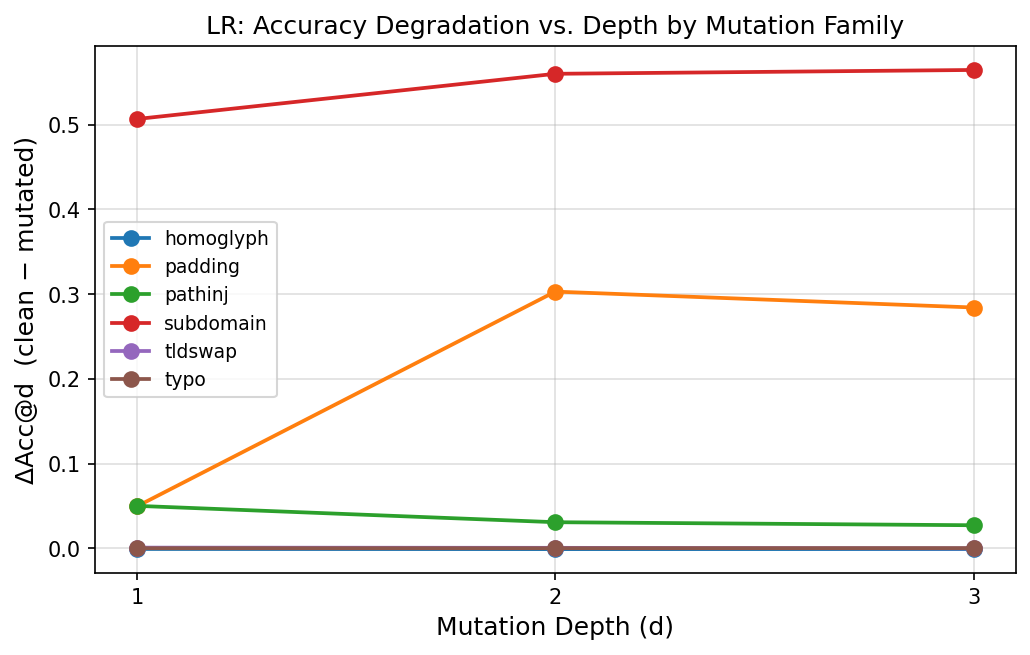

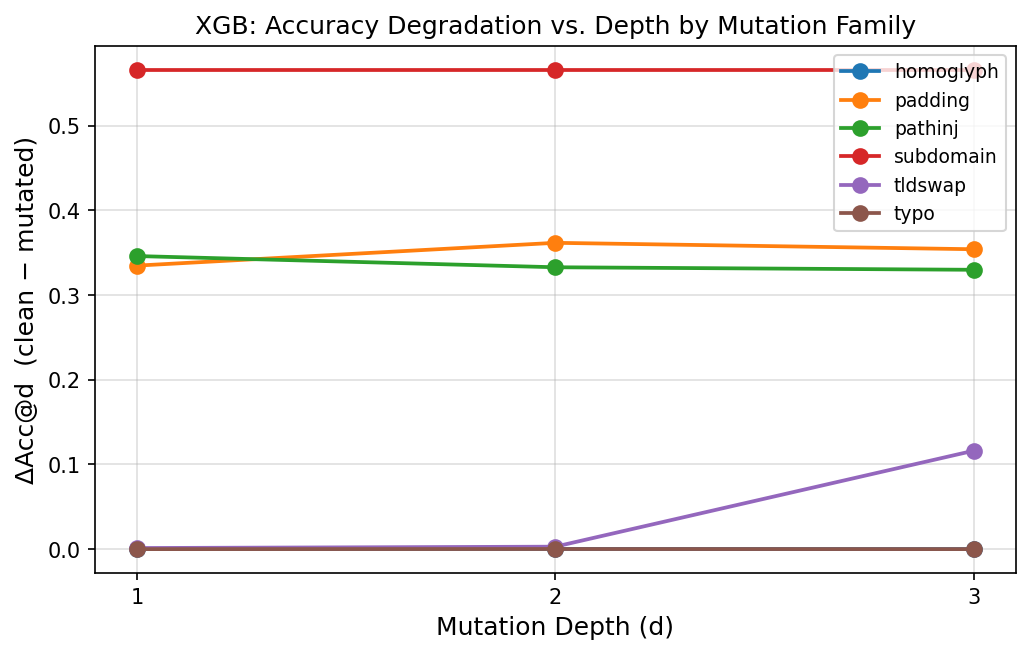

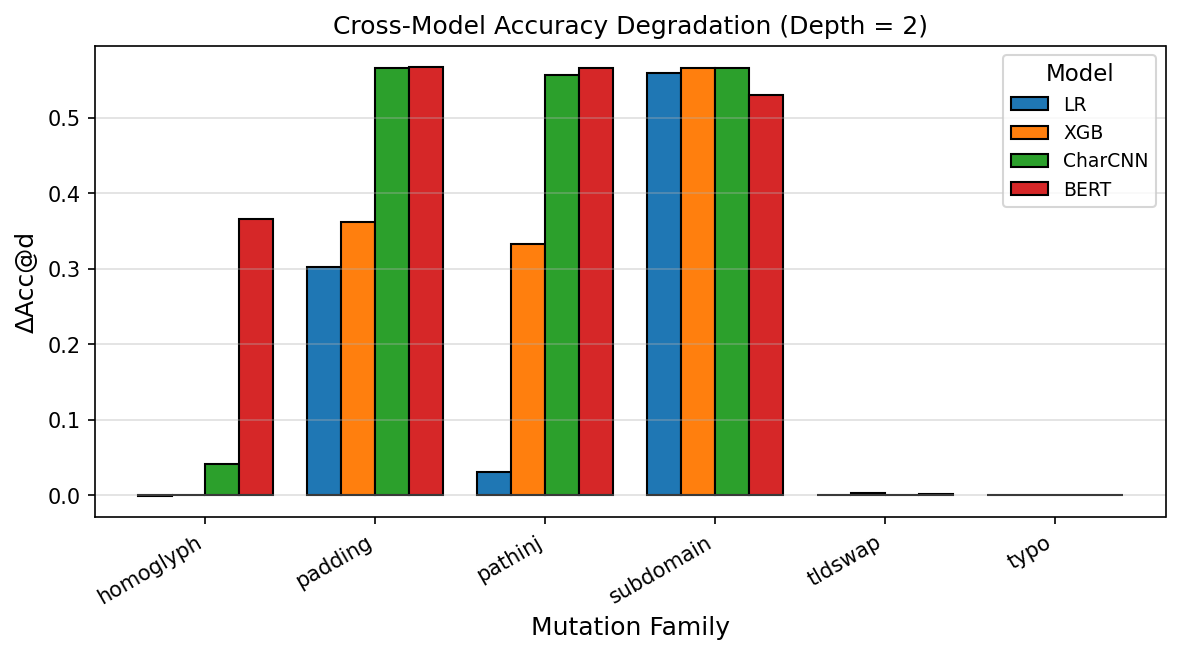

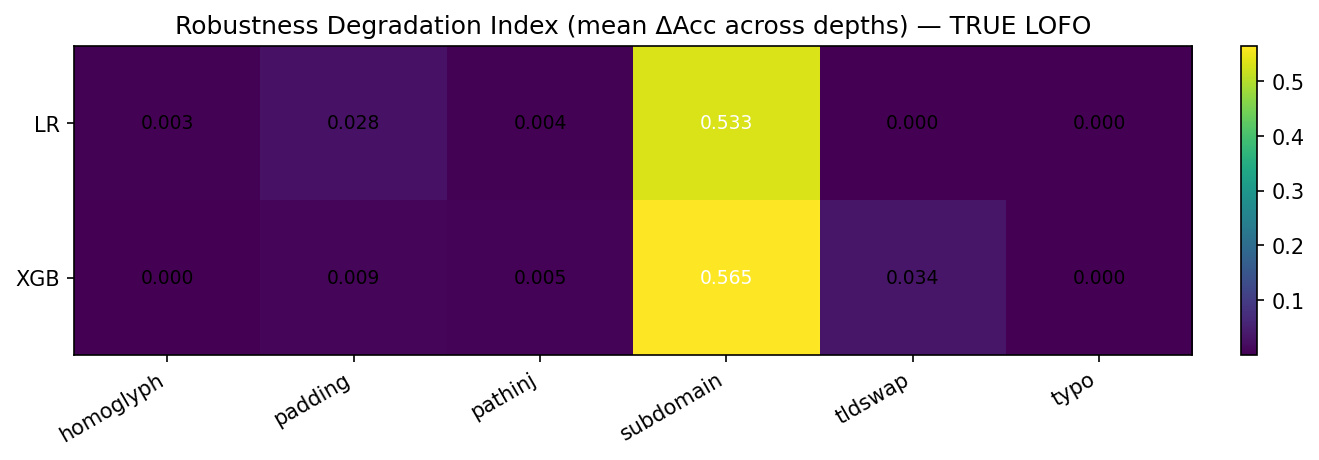

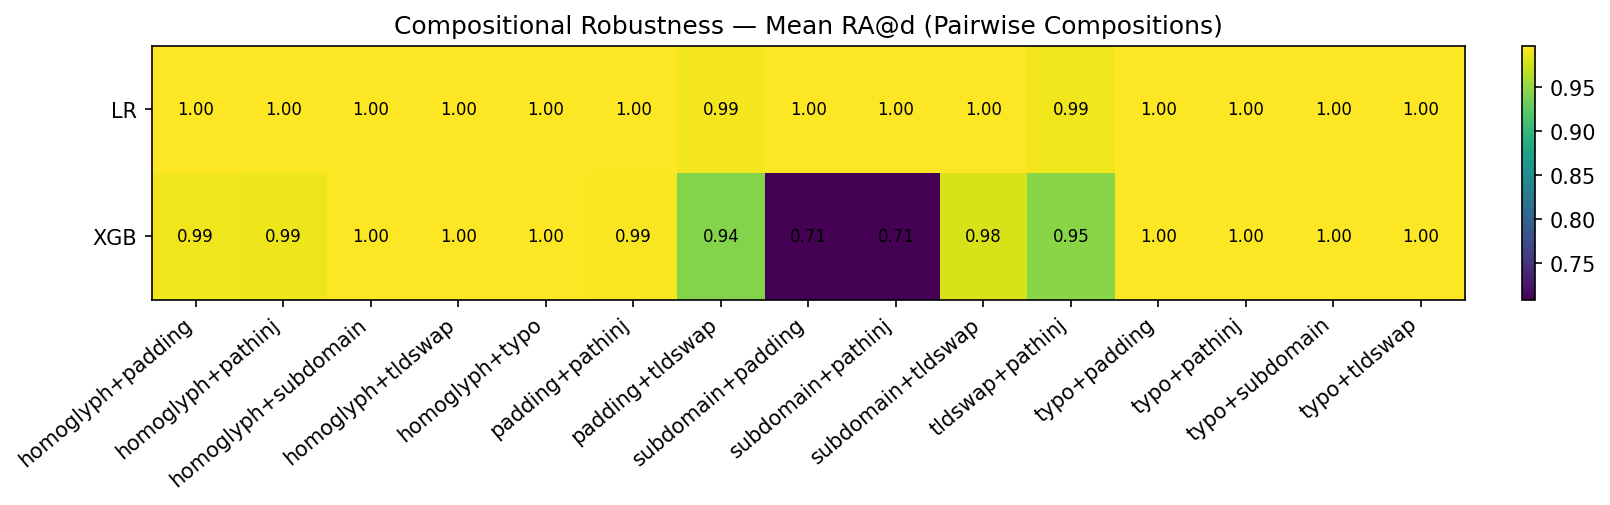

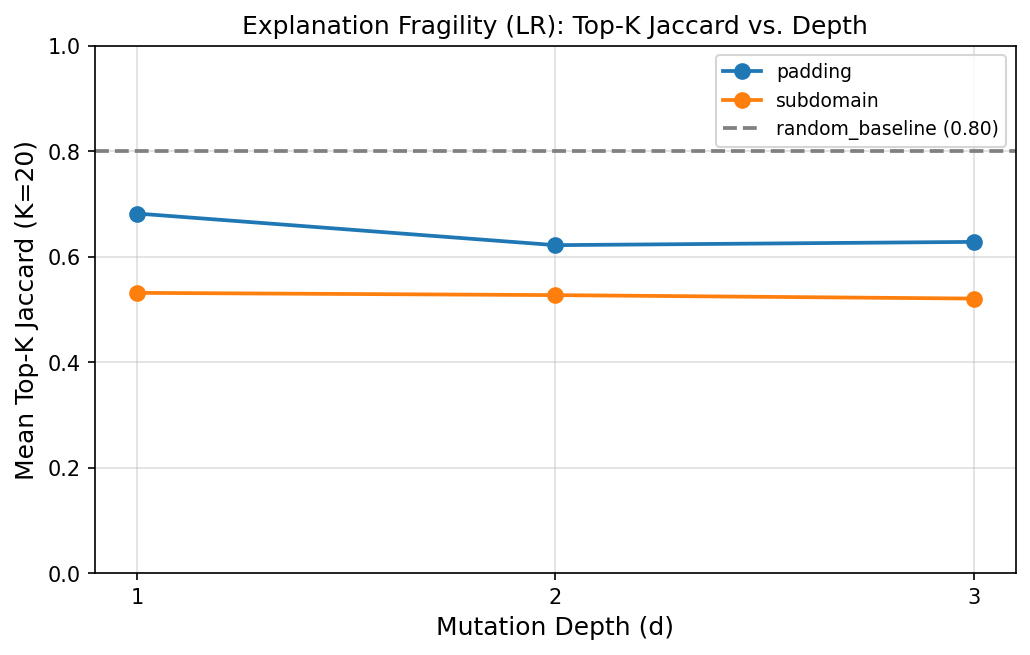

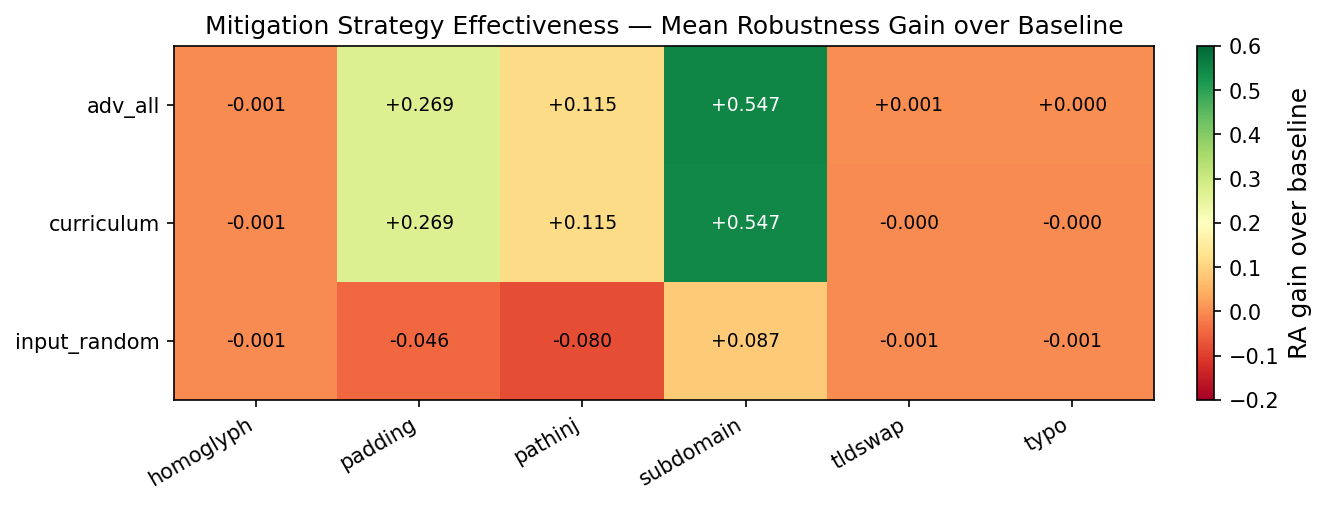

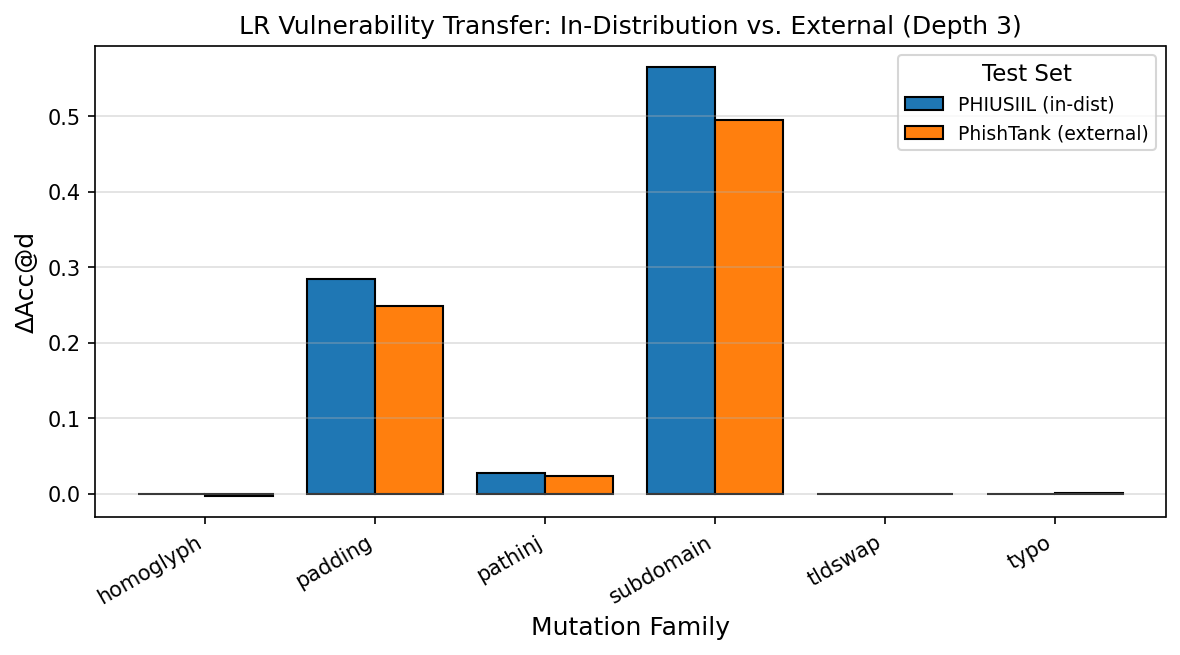


ALL PUBLICATION-QUALITY FIGURES SAVED to /content/plots/
  fig1_lr_delta_vs_depth.pdf  (15.8 KB)
  fig1_lr_delta_vs_depth.png  (309.6 KB)
  fig2_xgb_delta_vs_depth.pdf  (15.9 KB)
  fig2_xgb_delta_vs_depth.png  (295.3 KB)
  fig3_cross_model_d2_comparison.pdf  (14.4 KB)
  fig3_cross_model_d2_comparison.png  (329.3 KB)
  fig4_lofo_rdi_heatmap.pdf  (38.8 KB)
  fig4_lofo_rdi_heatmap.png  (325.4 KB)
  fig5_compositional_heatmap.pdf  (39.9 KB)
  fig5_compositional_heatmap.png  (904.8 KB)
  fig6_shap_fragility_lr.pdf  (13.8 KB)
  fig6_shap_fragility_lr.png  (247.4 KB)
  fig7_mitigation_effectiveness.pdf  (38.5 KB)
  fig7_mitigation_effectiveness.png  (421.7 KB)
  fig8_external_vs_indist_lr.pdf  (15.4 KB)
  fig8_external_vs_indist_lr.png  (338.5 KB)


In [ ]:
# === Cell 14 (replaces original): Publication-quality plots — Reviewer #13 ===
import os, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

# === Reviewer #13: publication-quality figure settings ===
mpl.rcParams.update({
    'figure.dpi':       150,    # screen preview
    'savefig.dpi':      600,    # publication-quality raster
    'font.size':        11,
    'axes.labelsize':   12,
    'axes.titlesize':   12,
    'xtick.labelsize':  10,
    'ytick.labelsize':  10,
    'legend.fontsize':  9,
    'savefig.bbox':     'tight',
    'pdf.fonttype':     42,     # embed fonts properly in PDFs
    'ps.fonttype':      42,
    'lines.linewidth':  1.8,
    'lines.markersize': 7,
})

os.makedirs("/content/plots", exist_ok=True)

# ---- Load all result tables ----
robust_phi_path  = "/content/robustness_phi_test.csv"
char_path        = "/content/robustness_phi_charcnn.csv"
bert_path        = "/content/robustness_phi_bert.csv"
lofo_path        = "/content/lofo_eval_TRUE.csv"
comp_sum_path    = "/content/compositional_summary.csv"
frag_path        = "/content/shap_fragility_lr.csv"
ext_lr_path      = "/content/robustness_phishtank_ext.csv"
ext_bert_path    = "/content/robustness_phishtank_ext_bert.csv"
mit_path         = "/content/mitigation_results.csv"
mit_gain_path    = "/content/mitigation_gains.csv"

robust_phi = pd.read_csv(robust_phi_path)
rob_char   = pd.read_csv(char_path)
rob_bert   = pd.read_csv(bert_path)
lofo       = pd.read_csv(lofo_path)
comp_sum   = pd.read_csv(comp_sum_path)
frag       = pd.read_csv(frag_path)
ext_lr     = pd.read_csv(ext_lr_path)
ext_bert   = pd.read_csv(ext_bert_path)
mit        = pd.read_csv(mit_path)
mit_gain   = pd.read_csv(mit_gain_path)

def save_both(name):
    """Save figure as both PDF (vector) and PNG (preview)."""
    plt.savefig(f"/content/plots/{name}.pdf", dpi=600)
    plt.savefig(f"/content/plots/{name}.png", dpi=600)


# =============================================================
# Fig 1: LR ΔAcc vs depth (per family)
# =============================================================
plt.figure(figsize=(7, 4.5))
fam_order = sorted(robust_phi['family'].unique())
for fam in fam_order:
    sub = robust_phi[(robust_phi['model']=="LR") & (robust_phi['family']==fam)].sort_values("depth")
    plt.plot(sub['depth'], sub['ΔAcc@d'], marker='o', label=fam)
plt.title("LR: Accuracy Degradation vs. Depth by Mutation Family")
plt.xlabel("Mutation Depth (d)")
plt.ylabel("ΔAcc@d  (clean − mutated)")
plt.xticks([1, 2, 3])
plt.legend(fontsize=9, loc='best')
plt.grid(alpha=0.4)
plt.tight_layout()
save_both("fig1_lr_delta_vs_depth")
plt.show()


# =============================================================
# Fig 2: XGB ΔAcc vs depth (per family)
# =============================================================
plt.figure(figsize=(7, 4.5))
for fam in fam_order:
    sub = robust_phi[(robust_phi['model']=="XGB") & (robust_phi['family']==fam)].sort_values("depth")
    plt.plot(sub['depth'], sub['ΔAcc@d'], marker='o', label=fam)
plt.title("XGB: Accuracy Degradation vs. Depth by Mutation Family")
plt.xlabel("Mutation Depth (d)")
plt.ylabel("ΔAcc@d  (clean − mutated)")
plt.xticks([1, 2, 3])
plt.legend(fontsize=9, loc='best')
plt.grid(alpha=0.4)
plt.tight_layout()
save_both("fig2_xgb_delta_vs_depth")
plt.show()


# =============================================================
# Fig 3 (NEW): Cross-model comparison at depth=2 (NEW PLOT)
# =============================================================
all_models = pd.concat([
    robust_phi[robust_phi['depth']==2][['model', 'family', 'depth', 'ΔAcc@d']],
    rob_char[rob_char['depth']==2][['model', 'family', 'depth', 'ΔAcc@d']],
    rob_bert[rob_bert['depth']==2][['model', 'family', 'depth', 'ΔAcc@d']],
])

pivot = all_models.pivot_table(index='family', columns='model', values='ΔAcc@d')
pivot = pivot.reindex(columns=['LR', 'XGB', 'CharCNN', 'BERT'])

fig, ax = plt.subplots(figsize=(8, 4.5))
pivot.plot(kind='bar', ax=ax, width=0.8, edgecolor='black')
plt.title("Cross-Model Accuracy Degradation (Depth = 2)")
plt.ylabel("ΔAcc@d")
plt.xlabel("Mutation Family")
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', alpha=0.4)
plt.legend(title="Model", fontsize=9)
plt.tight_layout()
save_both("fig3_cross_model_d2_comparison")
plt.show()


# =============================================================
# Fig 4: TRUE LOFO RDI heatmap
# =============================================================
lofo_grouped = (
    lofo.groupby(["model", "heldout_family"])["ΔAcc@d"]
        .mean().reset_index()
        .rename(columns={"heldout_family": "heldout", "ΔAcc@d": "RDI"})
)
models = ["LR", "XGB"]
heldouts = sorted(lofo_grouped['heldout'].unique())

mat = np.zeros((len(models), len(heldouts)))
for i, m in enumerate(models):
    for j, f in enumerate(heldouts):
        v = lofo_grouped[(lofo_grouped["model"]==m) & (lofo_grouped["heldout"]==f)]["RDI"]
        mat[i, j] = float(v.iloc[0]) if len(v) else np.nan

plt.figure(figsize=(9, 3.2))
im = plt.imshow(mat, aspect='auto', cmap="viridis")
plt.title("Robustness Degradation Index (mean ΔAcc across depths) — TRUE LOFO")
plt.yticks(range(len(models)), models)
plt.xticks(range(len(heldouts)), heldouts, rotation=30, ha="right")
plt.colorbar(im, fraction=0.046, pad=0.04)

for i in range(len(models)):
    for j in range(len(heldouts)):
        color = "white" if mat[i, j] > 0.3 else "black"
        plt.text(j, i, f"{mat[i, j]:.3f}", ha='center', va='center', fontsize=9, color=color)
plt.tight_layout()
save_both("fig4_lofo_rdi_heatmap")
plt.show()


# =============================================================
# Fig 5: Compositional pairs heatmap
# =============================================================
comp_mean = comp_sum.pivot(index="model", columns="pair", values="RA@d")
plt.figure(figsize=(min(13, 2 + 0.6 * comp_mean.shape[1]), 3.5))
im2 = plt.imshow(comp_mean, aspect='auto', cmap="viridis")
plt.title("Compositional Robustness — Mean RA@d (Pairwise Compositions)")
plt.xticks(range(comp_mean.shape[1]), comp_mean.columns, rotation=40, ha="right")
plt.yticks(range(comp_mean.shape[0]), comp_mean.index)
plt.colorbar(im2, fraction=0.046, pad=0.04)
for i in range(comp_mean.shape[0]):
    for j in range(comp_mean.shape[1]):
        color = "white" if comp_mean.iloc[i, j] < 0.7 else "black"
        plt.text(j, i, f"{comp_mean.iloc[i, j]:.2f}", ha='center', va='center', fontsize=8, color=color)
plt.tight_layout()
save_both("fig5_compositional_heatmap")
plt.show()


# =============================================================
# Fig 6: SHAP fragility (top-K Jaccard vs depth)
# =============================================================
plt.figure(figsize=(7, 4.5))
families_to_plot = [f for f in frag['family'].unique() if f != 'random_baseline']
for fam in families_to_plot:
    sub = frag[frag['family']==fam].sort_values("depth")
    plt.plot(sub['depth'], sub['mean_topK_jaccard'], marker='o', label=fam)
# Random baseline as horizontal reference line
rb = frag[frag['family']=='random_baseline']
if len(rb):
    rb_val = rb['mean_topK_jaccard'].iloc[0]
    plt.axhline(rb_val, ls='--', color='gray', label=f'random_baseline ({rb_val:.2f})')
plt.title("Explanation Fragility (LR): Top-K Jaccard vs. Depth")
plt.xlabel("Mutation Depth (d)")
plt.ylabel("Mean Top-K Jaccard (K=20)")
plt.xticks([1, 2, 3])
plt.ylim(0, 1)
plt.grid(alpha=0.4)
plt.legend(fontsize=9)
plt.tight_layout()
save_both("fig6_shap_fragility_lr")
plt.show()


# =============================================================
# Fig 7 (NEW): Mitigation strategies effectiveness
# =============================================================
gain_summary = (mit_gain.groupby(["regime", "family"])["gain"].mean()
                         .reset_index())
pivot_gain = gain_summary.pivot(index="regime", columns="family", values="gain")
pivot_gain = pivot_gain.reindex(["adv_all", "curriculum", "input_random"])

fig, ax = plt.subplots(figsize=(9, 3.5))
im3 = ax.imshow(pivot_gain.values, aspect='auto', cmap='RdYlGn',
                vmin=-0.2, vmax=0.6)
plt.title("Mitigation Strategy Effectiveness — Mean Robustness Gain over Baseline")
plt.xticks(range(pivot_gain.shape[1]), pivot_gain.columns, rotation=30, ha='right')
plt.yticks(range(pivot_gain.shape[0]), pivot_gain.index)
plt.colorbar(im3, fraction=0.046, pad=0.04, label='RA gain over baseline')
for i in range(pivot_gain.shape[0]):
    for j in range(pivot_gain.shape[1]):
        v = pivot_gain.iloc[i, j]
        plt.text(j, i, f"{v:+.3f}", ha='center', va='center', fontsize=9,
                 color="black" if abs(v) < 0.3 else "white")
plt.tight_layout()
save_both("fig7_mitigation_effectiveness")
plt.show()


# =============================================================
# Fig 8 (NEW): External vs in-distribution comparison (LR)
# =============================================================
in_dist_lr = robust_phi[robust_phi['model']=='LR'].copy()
in_dist_lr['source'] = 'PHIUSIIL (in-dist)'
ext_lr_lr = ext_lr[ext_lr['model']=='LR'].copy()
ext_lr_lr['source'] = 'PhishTank (external)'

combined = pd.concat([in_dist_lr, ext_lr_lr])
combined = combined[combined['depth']==3]  # focus on worst-case depth

fig, ax = plt.subplots(figsize=(8, 4.5))
pivot_ext = combined.pivot_table(index='family', columns='source', values='ΔAcc@d')
pivot_ext.plot(kind='bar', ax=ax, width=0.8, edgecolor='black')
plt.title("LR Vulnerability Transfer: In-Distribution vs. External (Depth 3)")
plt.ylabel("ΔAcc@d")
plt.xlabel("Mutation Family")
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', alpha=0.4)
plt.legend(title="Test Set", fontsize=9)
plt.tight_layout()
save_both("fig8_external_vs_indist_lr")
plt.show()


print("\n" + "=" * 70)
print(f"ALL PUBLICATION-QUALITY FIGURES SAVED to /content/plots/")
print("=" * 70)
for f in sorted(os.listdir("/content/plots")):
    path = os.path.join("/content/plots", f)
    size_kb = os.path.getsize(path) / 1024
    print(f"  {f}  ({size_kb:.1f} KB)")

In [ ]:
# === Cell 15 (NEW): Master Results Tables for Manuscript — Reviewer #14 ===
# Builds publication-ready summary tables consolidating all robustness results.
import pandas as pd
import numpy as np
import os

os.makedirs("/content/tables", exist_ok=True)

# ============================================================
# Load all result CSVs
# ============================================================
robust_phi  = pd.read_csv("/content/robustness_phi_test.csv")
rob_char    = pd.read_csv("/content/robustness_phi_charcnn.csv")
rob_bert    = pd.read_csv("/content/robustness_phi_bert.csv")
lofo        = pd.read_csv("/content/lofo_eval_TRUE.csv")
comp        = pd.read_csv("/content/compositional_results_fast.csv")
frag        = pd.read_csv("/content/shap_fragility_lr.csv")
ext_lr      = pd.read_csv("/content/robustness_phishtank_ext.csv")
ext_bert    = pd.read_csv("/content/robustness_phishtank_ext_bert.csv")
mit         = pd.read_csv("/content/mitigation_results.csv")
mit_gain    = pd.read_csv("/content/mitigation_gains.csv")
clean_main  = pd.read_csv("/content/clean_accuracy_results.csv")
split_stats = pd.read_csv("/content/split_stats.csv")

# Normalize column casing across files
def fmt_ci(row, val_col="RA@d", lo_col="RA_ci_lo", hi_col="RA_ci_hi"):
    return f"{row[val_col]:.4f} [{row[lo_col]:.4f}, {row[hi_col]:.4f}]"


# ============================================================
# TABLE 1: Dataset & Split Statistics (already saved)
# ============================================================
print("=" * 70)
print("TABLE 1 — Dataset & Domain-Disjoint Split Statistics")
print("=" * 70)
print(split_stats.to_string(index=False))
split_stats.to_csv("/content/tables/table1_dataset_splits.csv", index=False)


# ============================================================
# TABLE 2: Clean Accuracy with 95% CIs across all 4 models
# ============================================================
clean_all = pd.DataFrame([
    {"model": "LR",       "clean_acc": clean_main[clean_main['model']=='LR']['clean_acc'].iloc[0],
     "ci_lo": clean_main[clean_main['model']=='LR']['ci95_lo'].iloc[0],
     "ci_hi": clean_main[clean_main['model']=='LR']['ci95_hi'].iloc[0]},
    {"model": "XGB",      "clean_acc": clean_main[clean_main['model']=='XGB']['clean_acc'].iloc[0],
     "ci_lo": clean_main[clean_main['model']=='XGB']['ci95_lo'].iloc[0],
     "ci_hi": clean_main[clean_main['model']=='XGB']['ci95_hi'].iloc[0]},
    {"model": "CharCNN",  "clean_acc": rob_char['acc_clean'].iloc[0],
     "ci_lo": float('nan'), "ci_hi": float('nan')},
    {"model": "BERT",     "clean_acc": rob_bert['acc_clean'].iloc[0],
     "ci_lo": float('nan'), "ci_hi": float('nan')},
])
clean_all["acc_with_ci"] = clean_all.apply(
    lambda r: (f"{r['clean_acc']:.4f} [{r['ci_lo']:.4f}, {r['ci_hi']:.4f}]"
               if not pd.isna(r['ci_lo']) else f"{r['clean_acc']:.4f}"),
    axis=1
)
print("\n" + "=" * 70)
print("TABLE 2 — Clean Accuracy on PHIUSIIL Test Set (95% CI)")
print("=" * 70)
print(clean_all[["model", "acc_with_ci"]].to_string(index=False))
clean_all.to_csv("/content/tables/table2_clean_accuracy.csv", index=False)


# ============================================================
# TABLE 3: Master Robustness Matrix — RA@d for ALL (model × family × depth)
# ============================================================
all_rob_records = []
for src_df, mname in [(robust_phi[robust_phi['model']=='LR'],   'LR'),
                       (robust_phi[robust_phi['model']=='XGB'], 'XGB'),
                       (rob_char,  'CharCNN'),
                       (rob_bert,  'BERT')]:
    for _, r in src_df.iterrows():
        all_rob_records.append({
            "model":  mname,
            "family": r["family"],
            "depth":  int(r["depth"]),
            "RA@d":   round(r["RA@d"], 4),
            "ΔAcc@d": round(r["ΔAcc@d"], 4)
        })
master_rob = pd.DataFrame(all_rob_records)

# Pivot: rows = (family, depth), columns = model, values = RA@d
master_pivot_RA   = master_rob.pivot_table(index=["family", "depth"], columns="model", values="RA@d")
master_pivot_dA   = master_rob.pivot_table(index=["family", "depth"], columns="model", values="ΔAcc@d")

print("\n" + "=" * 70)
print("TABLE 3a — Robust Accuracy (RA@d) per Model × Family × Depth")
print("=" * 70)
print(master_pivot_RA.round(4).to_string())

print("\n" + "=" * 70)
print("TABLE 3b — Accuracy Degradation (ΔAcc@d) per Model × Family × Depth")
print("=" * 70)
print(master_pivot_dA.round(4).to_string())

master_pivot_RA.to_csv("/content/tables/table3a_RA_matrix.csv")
master_pivot_dA.to_csv("/content/tables/table3b_deltaAcc_matrix.csv")


# ============================================================
# TABLE 4: LOFO summary — generalization to unseen attack families
# ============================================================
lofo_summary = (lofo.groupby(["heldout_family", "model"])
                    .agg(mean_RA=("RA@d","mean"),
                         mean_dAcc=("ΔAcc@d","mean"),
                         max_dAcc=("ΔAcc@d","max"))
                    .reset_index()
                    .round(4))
print("\n" + "=" * 70)
print("TABLE 4 — LOFO Generalization (held-out family unseen during training)")
print("=" * 70)
print(lofo_summary.to_string(index=False))
lofo_summary.to_csv("/content/tables/table4_lofo_summary.csv", index=False)


# ============================================================
# TABLE 5: Compositional pairs (top vulnerable pairs)
# ============================================================
comp_summary = (comp.groupby(["pair", "model"])
                    .agg(mean_RA=("RA@d","mean"),
                         mean_dAcc=("ΔAcc@d","mean"))
                    .reset_index()
                    .round(4)
                    .sort_values(["model", "mean_RA"]))
print("\n" + "=" * 70)
print("TABLE 5 — Compositional Robustness (mean across orders & depths)")
print("=" * 70)
print(comp_summary.to_string(index=False))
comp_summary.to_csv("/content/tables/table5_compositional_summary.csv", index=False)


# ============================================================
# TABLE 6: SHAP fragility
# ============================================================
print("\n" + "=" * 70)
print("TABLE 6 — Explanation Fragility (LR, K=20 top features)")
print("=" * 70)
print(frag.round(4).to_string(index=False))
frag.to_csv("/content/tables/table6_shap_fragility.csv", index=False)


# ============================================================
# TABLE 7: External (PhishTank) robustness — vulnerability transfer
# ============================================================
ext_combined = pd.concat([
    ext_lr[["model", "family", "depth", "RA@d", "ΔAcc@d"]],
    ext_bert.rename(columns={"acc_clean": "ext_clean"})[["model","family","depth","RA@d","ΔAcc@d"]]
], ignore_index=True)
ext_summary = (ext_combined.groupby(["model","family"])
                            .agg(mean_RA=("RA@d","mean"),
                                 mean_dAcc=("ΔAcc@d","mean"))
                            .reset_index()
                            .round(4))
print("\n" + "=" * 70)
print("TABLE 7 — External Validation: Mean RA@d on PhishTank")
print("=" * 70)
print(ext_summary.to_string(index=False))
ext_summary.to_csv("/content/tables/table7_external_summary.csv", index=False)


# ============================================================
# TABLE 8: Mitigation Strategies — robustness gains over baseline
# ============================================================
mit_summary = (mit_gain.groupby(["regime", "family"])["gain"].mean()
                       .reset_index()
                       .round(4))
mit_pivot = mit_summary.pivot(index="regime", columns="family", values="gain")
mit_pivot["mean_gain"] = mit_pivot.mean(axis=1).round(4)
print("\n" + "=" * 70)
print("TABLE 8 — Mitigation Strategy Effectiveness (RA gain over baseline)")
print("=" * 70)
print(mit_pivot.round(4).to_string())
mit_pivot.to_csv("/content/tables/table8_mitigation_effectiveness.csv")


# ============================================================
# TABLE 9: Cross-model robustness gap @ depth=2 (averaged across families)
# ============================================================
gap = master_rob[master_rob['depth']==2].groupby('model').agg(
    mean_clean=('RA@d', lambda x: x.iloc[0]),  # placeholder - we'll fill below
    mean_RA=('RA@d', 'mean'),
    mean_dAcc=('ΔAcc@d', 'mean')
).reset_index().round(4)

# Build clean-acc reference per model
clean_ref = {
    'LR':      clean_main[clean_main['model']=='LR']['clean_acc'].iloc[0],
    'XGB':     clean_main[clean_main['model']=='XGB']['clean_acc'].iloc[0],
    'CharCNN': rob_char['acc_clean'].iloc[0],
    'BERT':    rob_bert['acc_clean'].iloc[0],
}
gap['mean_clean'] = gap['model'].map(clean_ref).round(4)
gap = gap[['model', 'mean_clean', 'mean_RA', 'mean_dAcc']]
gap = gap.sort_values('mean_dAcc')

print("\n" + "=" * 70)
print("TABLE 9 — Cross-Model Robustness Comparison @ Depth=2")
print("(averaged across all 6 mutation families)")
print("=" * 70)
print(gap.to_string(index=False))
gap.to_csv("/content/tables/table9_cross_model_gap.csv", index=False)


# ============================================================
# Final summary
# ============================================================
print("\n" + "=" * 70)
print("ALL PAPER TABLES SAVED to /content/tables/")
print("=" * 70)
for f in sorted(os.listdir("/content/tables")):
    path = os.path.join("/content/tables", f)
    size_kb = os.path.getsize(path) / 1024
    print(f"  {f}  ({size_kb:.2f} KB)")

TABLE 1 — Dataset & Domain-Disjoint Split Statistics
split  n_urls  n_domains  n_phishing  n_benign  phish_ratio
Train  164670     154055       70235     94435       0.4265
  Val   35173      33012       14951     20222       0.4251
 Test   35527      33012       15334     20193       0.4316

TABLE 2 — Clean Accuracy on PHIUSIIL Test Set (95% CI)
  model             acc_with_ci
     LR 0.9962 [0.9956, 0.9968]
    XGB 0.9974 [0.9968, 0.9979]
CharCNN                  0.9981
   BERT                  0.9984

TABLE 3a — Robust Accuracy (RA@d) per Model × Family × Depth
model              BERT  CharCNN      LR     XGB
family    depth                                 
homoglyph 1      0.7343   0.9733  0.9969  0.9972
          2      0.6324   0.9562  0.9971  0.9971
          3      0.5695   0.9388  0.9970  0.9973
padding   1      0.4317   0.4448  0.9467  0.6626
          2      0.4316   0.4316  0.6933  0.6357
          3      0.4316   0.4316  0.7120  0.6433
pathinj   1      0.4316   0.4325  0.9

In [ ]:
# === Cell 16 (NEW): Package all results for download ===
import shutil, os

# Bundle plots + tables + key CSVs
os.makedirs("/content/results_bundle", exist_ok=True)

# Copy plots
shutil.copytree("/content/plots", "/content/results_bundle/plots", dirs_exist_ok=True)
# Copy tables
shutil.copytree("/content/tables", "/content/results_bundle/tables", dirs_exist_ok=True)

# Copy core result CSVs
core_csvs = [
    "robustness_phi_test.csv",
    "robustness_phi_charcnn.csv",
    "robustness_phi_bert.csv",
    "lofo_eval_TRUE.csv",
    "lofo_sample_composition.csv",
    "compositional_results_fast.csv",
    "compositional_summary.csv",
    "compositional_order_diff.csv",
    "shap_fragility_lr.csv",
    "robustness_phishtank_ext.csv",
    "robustness_phishtank_ext_bert.csv",
    "clean_accuracy_results.csv",
    "clean_accuracy_phishtank.csv",
    "split_stats.csv",
    "dataset_stats.csv",
    "mitigation_results.csv",
    "mitigation_gains.csv",
    "cross_model_gap_d2.csv",
    "bert_training_curve.csv",
    "charcnn_training_curve.csv",
]
os.makedirs("/content/results_bundle/raw_csvs", exist_ok=True)
for f in core_csvs:
    src = f"/content/{f}"
    if os.path.exists(src):
        shutil.copy(src, f"/content/results_bundle/raw_csvs/{f}")
        print(f"  ✓ {f}")
    else:
        print(f"  ⚠ MISSING: {f}")

# Zip everything
shutil.make_archive("/content/results_bundle", "zip", "/content/results_bundle")
print(f"\n[saved] /content/results_bundle.zip")
print(f"  Size: {os.path.getsize('/content/results_bundle.zip')/1024:.1f} KB")

# Trigger download
from google.colab import files
files.download("/content/results_bundle.zip")

  ✓ robustness_phi_test.csv
  ✓ robustness_phi_charcnn.csv
  ✓ robustness_phi_bert.csv
  ✓ lofo_eval_TRUE.csv
  ✓ lofo_sample_composition.csv
  ✓ compositional_results_fast.csv
  ✓ compositional_summary.csv
  ✓ compositional_order_diff.csv
  ✓ shap_fragility_lr.csv
  ✓ robustness_phishtank_ext.csv
  ✓ robustness_phishtank_ext_bert.csv
  ✓ clean_accuracy_results.csv
  ✓ clean_accuracy_phishtank.csv
  ✓ split_stats.csv
  ✓ dataset_stats.csv
  ✓ mitigation_results.csv
  ✓ mitigation_gains.csv
  ✓ cross_model_gap_d2.csv
  ✓ bert_training_curve.csv
  ✓ charcnn_training_curve.csv

[saved] /content/results_bundle.zip
  Size: 2706.1 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# === Dual-source external validation: PhishTank phishing vs Tranco benign ===
# Uses live session objects: normalize_url, vectorizer, lr, xgb,
# model (CharCNN +encode_url/stoi/MAXLEN/device), bert_model (+tokenizer/DEVICE).
# Nothing retrained. Reports per-class metrics + AUROC/AUPRC + confusion matrices.
# Also re-runs the source-separation diagnostic so you can see the confound alongside.
import os, io, zipfile, urllib.request
import numpy as np, pandas as pd, torch
from urllib.parse import urlparse
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

OUT = "/content/reviewer_addon"; os.makedirs(OUT, exist_ok=True)
def host_of(u):
    h = (urlparse(str(u)).netloc or "").lower()
    return h[4:] if h.startswith("www.") else h

# 1. External PHISHING = PhishTank (already normalized in your Cell 0)
pt = pd.read_csv("/content/phishtank_normalized.csv")
pt["host"] = pt["URL_norm"].map(host_of)
pt = pt[pt["host"] != ""].drop_duplicates("host")
n_ext = len(pt)
print(f"[external] PhishTank phishing hosts: {n_ext}")

# 2. External BENIGN = Tranco (independent source)
raw = urllib.request.urlopen("https://tranco-list.eu/top-1m.csv.zip", timeout=120).read()
with zipfile.ZipFile(io.BytesIO(raw)) as z:
    tr = pd.read_csv(z.open(z.namelist()[0]), names=["rank", "domain"])
tr["host"] = tr["domain"].astype(str).str.lower().str.replace(r"^www\.", "", regex=True)
tr = tr[tr["host"] != ""].drop_duplicates("host").sample(n=n_ext, random_state=SEED)
print(f"[external] Tranco benign hosts: {len(tr)}")

# 3. Host-level set for BOTH classes, normalized via YOUR pipeline
ext = pd.concat([
    pd.DataFrame({"URL": "https://" + pt["host"].values, "label": 1}),
    pd.DataFrame({"URL": "https://" + tr["host"].values, "label": 0}),
], ignore_index=True).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
ext["URL_norm"] = ext["URL"].map(normalize_url)
y_ext = ext["label"].to_numpy()
texts = ext["URL_norm"].astype(str).tolist()
ext.to_csv(f"{OUT}/external_dualsource_set.csv", index=False)
print(f"[external] balanced set: {len(ext)} ({n_ext} phish + {n_ext} benign)")

# 3b. Source-separation confound (junk features only) — report alongside
def feats(h):
    return [len(h), h.count("."), sum(c.isdigit() for c in h)/max(len(h),1),
            len(h.split(".")[-1]), int(h.split(".")[-1] in {"com","net","org"}),
            sum(c=="-" for c in h)]
Xs = np.array([feats(h) for h in pd.concat([pt["host"], tr["host"]])])
ys = np.r_[np.ones(n_ext), np.zeros(n_ext)]
sep_auc = cross_val_score(LogisticRegression(max_iter=1000), Xs, ys, cv=5, scoring="roc_auc").mean()
print(f"[confound] source-separation AUROC on junk features: {sep_auc:.4f}")

# 4. Score each model (no retraining)
Xv = vectorizer.transform(texts)
scores = {"LR": lr.predict_proba(Xv)[:, 1], "XGB": xgb.predict_proba(Xv)[:, 1]}

model.eval()
with torch.no_grad():
    xb = torch.from_numpy(np.stack([encode_url(t) for t in texts])).to(device)
    scores["CharCNN"] = np.concatenate(
        [model(xb[i:i+512]).softmax(-1)[:, 1].cpu().numpy() for i in range(0, len(xb), 512)])

bert_model.eval()
with torch.no_grad():
    chunks = []
    for i in range(0, len(texts), 64):
        enc = tokenizer(texts[i:i+64], padding=True, truncation=True,
                        max_length=128, return_tensors="pt").to(DEVICE)
        chunks.append(bert_model(**enc).logits.softmax(-1)[:, 1].cpu().numpy())
    scores["BERT"] = np.concatenate(chunks)

# 5. Per-class metrics + confusion matrix (threshold 0.5)
rows = []
for name, s in scores.items():
    yp = (s >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_ext, yp, labels=[0, 1]).ravel()
    rows.append({"model": name,
        "accuracy": accuracy_score(y_ext, yp),
        "phish_P": precision_score(y_ext, yp, zero_division=0),
        "phish_R": recall_score(y_ext, yp, zero_division=0),
        "phish_F1": f1_score(y_ext, yp, zero_division=0),
        "benign_R": tn/(tn+fp) if (tn+fp) else np.nan,
        "FPR": fp/(fp+tn) if (fp+tn) else np.nan,
        "FNR": fn/(fn+tp) if (fn+tp) else np.nan,
        "AUROC": roc_auc_score(y_ext, s),
        "AUPRC": average_precision_score(y_ext, s),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp})
    np.savez(f"{OUT}/scores_external_{name}.npz", y_true=y_ext, y_score=s, y_pred=yp)

res = pd.DataFrame(rows)
res.to_csv(f"{OUT}/external_dualsource_metrics.csv", index=False)
pd.set_option("display.width", 220)
print("\n=== DUAL-SOURCE EXTERNAL (PhishTank phishing vs Tranco benign) ===")
print(res.round(4).to_string(index=False))
print("\nConfusion (rows=true[benign,phish] cols=pred[benign,phish]):")
for r in rows:
    print(f"  {r['model']:8s} TN={r['TN']:6d} FP={r['FP']:6d} | FN={r['FN']:6d} TP={r['TP']:6d}")
print(f"\n[saved] {OUT}/external_dualsource_metrics.csv  +  scores_external_*.npz")
print(f"AUPRC no-skill baseline = 0.5000 | source-separation confound AUROC = {sep_auc:.4f}")

[point8] PHIUSIIL test N=35527  phishing=15334  benign=20193  prevalence=0.4316

=== POINT 8 — per-class metrics (clean + worst-case) ===
  model        setting    acc  phish_P  phish_R  phish_F1  benign_P  benign_R    FPR    FNR  AUROC  AUPRC
     LR          clean 0.9962   1.0000   0.9912    0.9956    0.9934    1.0000 0.0000 0.0088 0.9988 0.9990
     LR subdomain(d=3) 0.4319   0.4317   1.0000    0.6031    1.0000    0.0005 0.9995 0.0000 0.9982 0.9983
    XGB          clean 0.9974   0.9996   0.9943    0.9970    0.9957    0.9997 0.0003 0.0057 0.9988 0.9990
    XGB subdomain(d=3) 0.4316   0.4316   1.0000    0.6030    0.0000    0.0000 1.0000 0.0000 0.9405 0.9321
CharCNN          clean 0.9981   0.9999   0.9958    0.9978    0.9968    0.9999 0.0001 0.0042 0.9990 0.9992
CharCNN   padding(d=2) 0.4316   0.4316   1.0000    0.6030    0.0000    0.0000 1.0000 0.0000 0.7356 0.5898
   BERT          clean 0.9984   1.0000   0.9963    0.9982    0.9972    1.0000 0.0000 0.0037 0.9992 0.9993
   BERT homogl

In [ ]:
# === POINT 5: Dual-source external validation (PhishTank phishing vs Majestic benign) ===
# Reviewer fix: external BENIGN now comes from an INDEPENDENT source (Majestic
# Million, a plain single CSV) instead of PHIUSIIL. Also reports the
# SOURCE-SEPARATION confound AUROC (the deeper issue: is the model separating
# phishing-vs-benign, or just source-A-vs-source-B?), plus per-family robust
# accuracy on the dual-source set so manuscript Section 4.6 stays consistent.
# Nothing retrained.
# Live objects used: normalize_url, FAMILIES/mutate_*, vectorizer, lr, xgb,
#   model+encode_url+device (CharCNN), bert_model+tokenizer+DEVICE (BERT).
import os, random
import numpy as np, pandas as pd, torch
from urllib.parse import urlparse
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

OUT = "/content/reviewer_addon"; os.makedirs(OUT, exist_ok=True)
pd.set_option("display.width", 240); pd.set_option("display.max_columns", 40)

def host_of(u):
    h = (urlparse(str(u)).netloc or "").lower()
    return h[4:] if h.startswith("www.") else h

# 1. External PHISHING = PhishTank (already normalized in your data cell)
pt = pd.read_csv("/content/phishtank_normalized.csv")
pt["host"] = pt["URL_norm"].map(host_of)
pt = pt[pt["host"] != ""].drop_duplicates("host")
n_ext = len(pt)
print(f"[external] PhishTank phishing hosts: {n_ext}")

# 2. External BENIGN = Majestic Million (independent source, single plain CSV — easy)
tr = pd.read_csv("https://downloads.majestic.com/majestic_million.csv")
tr["host"] = tr["Domain"].astype(str).str.lower().str.replace(r"^www\.", "", regex=True)
tr = tr[tr["host"] != ""].drop_duplicates("host").sample(n=n_ext, random_state=SEED)
print(f"[external] Majestic benign hosts:    {len(tr)}")

# 3. Balanced host-level set, normalized through YOUR pipeline
ext = pd.concat([
    pd.DataFrame({"URL": "https://" + pt["host"].values, "label": 1}),
    pd.DataFrame({"URL": "https://" + tr["host"].values, "label": 0}),
], ignore_index=True).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
ext["URL_norm"] = ext["URL"].map(normalize_url)
y_ext = ext["label"].to_numpy()
base  = ext["URL_norm"].astype(str).tolist()
ext.to_csv(f"{OUT}/external_dualsource_set.csv", index=False)
print(f"[external] balanced set: {len(ext)} ({n_ext} phish + {n_ext} benign)")

# 3b. SOURCE-SEPARATION CONFOUND: can junk host features alone tell the two
#     sources apart? High AUROC here => dual-source result still confounded.
def feats(h):
    return [len(h), h.count("."), sum(c.isdigit() for c in h)/max(len(h),1),
            len(h.split(".")[-1]), int(h.split(".")[-1] in {"com","net","org"}),
            sum(c=="-" for c in h)]
Xs = np.array([feats(h) for h in pd.concat([pt["host"], tr["host"]])])
ys = np.r_[np.ones(n_ext), np.zeros(n_ext)]
sep_auc = cross_val_score(LogisticRegression(max_iter=1000), Xs, ys, cv=5, scoring="roc_auc").mean()
print(f"[confound] source-separation AUROC on junk features: {sep_auc:.4f}  "
      f"(near 0.5 = good; high = dual-source result still confounded)")

# 4. Probability scorers (no retraining)
def s_lr(u):  return lr.predict_proba(vectorizer.transform(u))[:, 1]
def s_xgb(u): return xgb.predict_proba(vectorizer.transform(u))[:, 1]
def s_cnn(u):
    model.eval()
    with torch.no_grad():
        xb = torch.from_numpy(np.stack([encode_url(x) for x in u])).to(device)
        return np.concatenate([model(xb[i:i+512]).softmax(-1)[:,1].cpu().numpy()
                               for i in range(0, len(xb), 512)])
def s_bert(u):
    bert_model.eval(); out=[]
    with torch.no_grad():
        for i in range(0, len(u), 64):
            enc = tokenizer(u[i:i+64], padding=True, truncation=True,
                            max_length=128, return_tensors="pt").to(DEVICE)
            out.append(bert_model(**enc).logits.softmax(-1)[:,1].cpu().numpy())
    return np.concatenate(out)
SC = {"LR": s_lr, "XGB": s_xgb, "CharCNN": s_cnn, "BERT": s_bert}

# 5. CLEAN dual-source per-class metrics + confusion (threshold 0.5)
def metrics(name, setting, y_true, s):
    yp = (s >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, yp, labels=[0,1]).ravel()
    return {"model":name, "setting":setting, "acc":accuracy_score(y_true,yp),
        "phish_P":precision_score(y_true,yp,zero_division=0),
        "phish_R":recall_score(y_true,yp,zero_division=0),
        "phish_F1":f1_score(y_true,yp,zero_division=0),
        "benign_R":recall_score(y_true,yp,pos_label=0,zero_division=0),
        "FPR":fp/(fp+tn) if (fp+tn) else np.nan,
        "FNR":fn/(fn+tp) if (fn+tp) else np.nan,
        "AUROC":roc_auc_score(y_true,s), "AUPRC":average_precision_score(y_true,s),
        "TP":tp,"FP":fp,"FN":fn,"TN":tn}

clean_scores = {m: SC[m](base) for m in SC}
clean_rows = [metrics(m, "clean", y_ext, clean_scores[m]) for m in SC]
CLEAN = pd.DataFrame(clean_rows)
CLEAN.to_csv(f"{OUT}/point5_dualsource_clean.csv", index=False)
print("\n=== POINT 5 — DUAL-SOURCE clean per-class (PhishTank phish vs Majestic benign) ===")
print(CLEAN[["model","acc","phish_P","phish_R","phish_F1","benign_R","FPR","FNR","AUROC","AUPRC"]]
      .round(4).to_string(index=False))

# 6. Per-family robust accuracy on the dual-source set (mirrors manuscript Section 4.6).
#    Reseed before each (family,depth) so it is reproducible.
print("\n=== POINT 5 — DUAL-SOURCE per-family robust accuracy (mean ΔAcc across depths) ===")
clean_acc = {m: ((clean_scores[m] >= 0.5).astype(int) == y_ext).mean() for m in SC}
rob_rows = []
for fam in FAMILIES:
    for d in (1,2,3):
        random.seed(SEED)
        fn = FAMILIES[fam]
        mut = [normalize_url(fn(u, depth=d)) for u in base]
        for m in SC:
            yp = (SC[m](mut) >= 0.5).astype(int)
            ra = (yp == y_ext).mean()
            rob_rows.append({"model":m, "family":fam, "depth":d,
                             "ext_clean_acc":clean_acc[m], "RA@d":ra,
                             "dAcc@d":clean_acc[m]-ra})
ROB = pd.DataFrame(rob_rows)
ROB.to_csv(f"{OUT}/point5_dualsource_robust.csv", index=False)
piv = ROB.groupby(["model","family"])["dAcc@d"].mean().round(4).unstack("family")
print(piv.to_string())

print(f"\n[saved] {OUT}/point5_dualsource_clean.csv  point5_dualsource_robust.csv  external_dualsource_set.csv")
print(f"[report in letter] dual-source clean acc above + source-separation AUROC = {sep_auc:.4f}")

[external] PhishTank phishing hosts: 22944
[external] Majestic benign hosts:    22944
[external] balanced set: 45888 (22944 phish + 22944 benign)
[confound] source-separation AUROC on junk features: 0.9235  (near 0.5 = good; high = dual-source result still confounded)

=== POINT 5 — DUAL-SOURCE clean per-class (PhishTank phish vs Majestic benign) ===
  model    acc  phish_P  phish_R  phish_F1  benign_R    FPR    FNR  AUROC  AUPRC
     LR 0.5356   0.5188   0.9826    0.6790    0.0886 0.9114 0.0174 0.8981 0.9233
    XGB 0.5000   0.5000   1.0000    0.6667    0.0000 1.0000 0.0000 0.6640 0.6855
CharCNN 0.4977   0.4988   0.9940    0.6643    0.0014 0.9986 0.0060 0.8451 0.8780
   BERT 0.4968   0.4984   0.9934    0.6638    0.0001 0.9999 0.0066 0.8437 0.8662

=== POINT 5 — DUAL-SOURCE per-family robust accuracy (mean ΔAcc across depths) ===
family   homoglyph  padding  pathinj  subdomain  tldswap    typo
model                                                           
BERT       -0.0029  -0.0032 

In [ ]:
# ==========================
# SAVE ALL TRAINED MODELS
# ==========================

import joblib
import torch
import os

os.makedirs("saved_models", exist_ok=True)

# Save TF-IDF Vectorizer
joblib.dump(vectorizer, "saved_models/tfidf_vectorizer.pkl")

# Save Logistic Regression
joblib.dump(lr, "saved_models/logistic_regression.pkl")

# Save XGBoost
joblib.dump(xgb, "saved_models/xgboost.pkl")

# Save CharCNN
torch.save(model.state_dict(),
           "saved_models/charcnn_weights.pth")

# Save BERT
bert_model.save_pretrained("saved_models/bert_model")
tokenizer.save_pretrained("saved_models/bert_model")

print("✓ All models saved successfully")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✓ All models saved successfully


In [ ]:
import joblib
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# LR
lr = joblib.load("saved_models/logistic_regression.pkl")

# XGB
xgb = joblib.load("saved_models/xgboost.pkl")

# Vectorizer
vectorizer = joblib.load("saved_models/tfidf_vectorizer.pkl")

# BERT
tokenizer = AutoTokenizer.from_pretrained("saved_models/bert_model")
bert_model = AutoModelForSequenceClassification.from_pretrained(
    "saved_models/bert_model"
)

# CharCNN
charcnn = CharCNN().to(device)
charcnn.load_state_dict(
    torch.load("saved_models/charcnn_weights.pth",
               map_location=device)
)
charcnn.eval()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

CharCNN(
  (emb): Embedding(60, 32, padding_idx=0)
  (conv): Sequential(
    (0): Conv1d(32, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): ReLU()
    (2): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (3): ReLU()
    (4): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv1d(128, 256, kernel_size=(3,), stride=(1,), padding=(1,))
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Linear(in_features=8192, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=2, bias=True)
  )
)

In [ ]:
!zip -r saved_models.zip saved_models

from google.colab import files
files.download("saved_models.zip")

  adding: saved_models/ (stored 0%)
  adding: saved_models/bert_model/ (stored 0%)
  adding: saved_models/bert_model/tokenizer.json (deflated 71%)
  adding: saved_models/bert_model/tokenizer_config.json (deflated 44%)
  adding: saved_models/bert_model/model.safetensors (deflated 7%)
  adding: saved_models/bert_model/config.json (deflated 53%)
  adding: saved_models/logistic_regression.pkl (deflated 14%)
  adding: saved_models/tfidf_vectorizer.pkl (deflated 59%)
  adding: saved_models/charcnn_weights.pth (deflated 7%)
  adding: saved_models/xgboost.pkl (deflated 72%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>